# Лабораторная работа №6: Построение и оценка VLM-пайплайна
## Стрельченко Алексей Александрович

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Запустить quantized VLM 2–4B.
- Создать evaluation JSONL.
- Сравнить prompts, resolution и decoding; разметить ошибки.


## Теоретическая часть

VLM связывает visual encoder, projector и language model. Оценка должна разделять captioning, VQA, OCR и structured extraction, фиксировать prompt, decoding и ошибки: hallucination, counting, spatial relations.

![Пример изображения для Visual Question Answering](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/vqa-example.png)


### Математическая постановка

Для открытых ответов одной exact match недостаточно. Используют нормализованный EM/F1, judge rubric и ручную разметку ошибок. Hallucination rate: $H=N_{unsupported}/N_{claims}$.


### Материалы

- [Transformers multimodal chat templates](https://huggingface.co/docs/transformers/chat_templating_multimodal)
- [VLMEvalKit](https://github.com/open-compass/VLMEvalKit)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Запустить quantized VLM 2–4B.
2. Создать evaluation JSONL.
3. Сравнить prompts, resolution и decoding; разметить ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** VLM 4B NF4 inference, одно изображение.
- **Ограничение данных:** 20 evaluation examples: 5 на каждый из четырёх типов задач.
- **Fallback:** VLM 2B NF4 с тем же API.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и инференсу; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


**Vision-Language Model (VLM)** — это нейросеть, которая на входе получает изображение и текст, а на выходе возвращает текст. Архитектурно VLM состоит из трёх частей: visual encoder (обычно Vision Transformer, ViT), который превращает картинку в набор эмбеддингов патчей; projector, который переводит эти эмбеддинги в пространство языковой модели; и language model (LLM), которая авторегрессионно генерирует текстовый ответ, «видя» одновременно и визуальные токены, и текстовые. Именно поэтому VLM может отвечать на вопросы по картинке, описывать её, извлекать из неё текст и выдавать структурированные данные — всё в одной модели, без отдельных голов под каждую задачу.  

Оценивать VLM существенно сложнее, чем классический классификатор. У классификатора есть один правильный ответ и одна метрика accuracy. У VLM правильных ответов может быть бесконечно много: «a brown dog on grass», «the dog is brown and sitting on grass», «a brown canine outdoors» — все три верны, но попарный exact match даст ноль. Именно поэтому оценка VLM строится как минимум на трёх уровнях: автоматическая метрика (нормализованный EM и F1) для коротких ответов; ручная экспертная разметка для описаний и типов ошибок; latency-бюджет для реального применения.   

Его обучают в три этапа, каждый из которых решает свою задачу.  

**Этап 1: Pretraining**  
На этом этапе берут огромный датасет пар «изображение — подпись» (миллионы или миллиарды пар). Например, картинка кота и подпись «a ginger cat sitting on a windowsill». Модель учат, чтобы вектор картинки и вектор её подписи были близки в общем пространстве, а вектор картинки и вектор чужой подписи — далеки.  

Обучение идёт через контрастивный лосс (contrastive loss). Идея: берём батч из 100 пар. Для каждой картинки правильная подпись — её собственная, все остальные 99 подписей в батче — «неправильные». Модель должна так настроить веса, чтобы для каждой картинки её подпись была ближе всех остальных. Модель как будто решает задачу «найди мою подпись среди чужих». Так визуальный энкодер и проектор учатся выравнивать картинки и текст в общем пространстве. После этого этапа модель уже «понимает», что «кот» и фотография кота — близкие вещи.  

**Этап 2: Instruction tuning**  
После первого этапа модель «видит» картинки, но не умеет нормально отвечать на вопросы. Она может сказать «кот» на картинку кота, но не ответит на «сколько лап у кота на картинке?». Нужен второй этап — instruction tuning (настройка на инструкции).  

На этом этапе берут датасет из пар «(картинка, вопрос) — правильный ответ». Например:  
- Картинка кота + «что на картинке?» → «рыжий кот»  
- Та же картинка + «какого цвета кот?» → «рыжий».  
- Та же картинка + «сколько лап видно?» → «четыре».  

Модель обучается предсказывать правильный ответ. Этот этап учит её следовать инструкциям, отвечать развёрнуто, понимать разные типы вопросов. Датасеты для этого этапа часто собирают вручную или полуавтоматически — например, через ChatGPT, который генерирует вопросы и ответы по картинкам.  

Именно на этом этапе модель учится решать разные задачи: VQA (вопрос-ответ), captioning (описание), OCR (чтение текста), диалоги (многошаговый разговор про картинку). Все эти задачи перемешаны в одном датасете, и модель учится переключаться между ними в зависимости от формулировки запроса.  

**Этап 3: Alignment**  
После двух первых этапов модель работает, но может выдавать нежелательные ответы: грубить, помогать в незаконных задачах, галлюцинировать, повторять предрассудки из интернета. Третий этап — alignment (выравнивание) — учит модель отвечать так, как хочет человек.  

Два основных подхода: RLHF (Reinforcement Learning from Human Feedback) и DPO (Direct Preference Optimization).  

**RLHF** работает так: люди смотрят на ответы модели и оценивают их («этот ответ хороший», «этот плохой»). Из этих оценок обучают reward model — модель-судью, которая предсказывает, понравится ли ответ человеку. Затем основную модель дообучают через reinforcement learning так, чтобы максимизировать reward. Идея: пусть модель сама генерирует много ответов, а reward model подсказывает, какие из них хорошие.  

**DPO** — более простой вариант: не нужна отдельная reward model. Просто берут пары «хороший ответ, плохой ответ» на один и тот же запрос и обучают модель предпочитать хорошие. Технически это делается через специальную функцию лосса, которая увеличивает вероятность хороших ответов и уменьшает вероятность плохих.  

Без alignment модель может быть опасной или бесполезной: слишком многословной, грубой, склонной к галлюцинациям. С alignment она ведёт себя так, как ожидает пользователь. Именно на этом этапе модель учится говорить «не знаю» вместо того, чтобы придумывать, отказываться от небезопасных запросов, отвечать вежливо.  

У обычной модели-классификатора (например, «определи, кошка или собака на картинке») есть один правильный ответ из маленького набора. Метрика — accuracy: сколько раз модель угадала.   

**У VLM — три проблемы.**  

**Проблема первая: много правильных ответов.** На вопрос «опиши картинку» может быть тысяча правильных ответов. Все они верны, но строки разные. Если сравнивать буквально, все дадут ноль.  

**Проблема вторая: открытые ответы.** В captioning нет «правильного ответа» — есть «хороший», «приемлемый», «плохой». Это субъективные категории, их нельзя вычислить формулой.  

**Проблема третья: специфические ошибки.** VLM может наврать так, как классификатор не может.  

Нужна многоуровневая система: автоматические метрики для простых случаев, ручная разметка для сложных, отдельный анализ ошибок, отдельная оценка latency.  

**Exact Match (EM)** — точное совпадение. Сравниваем ответ модели с эталоном посимвольно. Если совпадает — 1, иначе — 0. Просто, но слишком строго: «cat» и «Cat.» — разные строки, хотя смысл один.  

Чтобы EM был честнее, ответы нормализуют перед сравнением: приводят к нижнему регистру, удаляют артикли (a, an, the), знаки препинания, лишние пробелы. После нормализации «Cat.» и «the cat» совпадут. Это стандарт в SQuAD, VQA, GQA.  

**Token F1.** Мягкая метрика. Разбиваем предсказание и эталон на токены (слова) и считаем пересечение. Например:  
Предсказание: «a brown cat» → токены [a, brown, cat].  
Эталон: «a cat» → токены [a, cat].  
Общих токенов: 2 (a и cat).  
Precision = 2/3 (из 3 предсказанных 2 верных).  
Recall = 2/2 (из 2 эталонных 2 нашла).  
F1 = 2 × (2/3) × 1 / ((2/3) + 1) ≈ 0.8.  

**LLM-as-Judge.** Даём ответ модели и эталон большой LLM (например, GPT-4) и спрашиваем: «этот ответ правильный?». LLM отвечает «да/нет/частично» плюс объяснение.   

**Benchmark** — это стандартный набор задач для сравнения моделей. Идея: если у всех исследователей один и тот же набор, можно честно сравнивать результаты. Без benchmark'ов каждый бы тестировал на своих данных, и сравнение было бы невозможно.  

**PixMo (от Allen AI)** — открытый набор датасетов, использованный в этой лабораторной. Четыре поднабора: PixMo-Cap (описания), PixMo-AskModelAnything (VQA), PixMo-Docs (документы), PixMo-Count (счёт объектов). Лицензия ODC-BY-1.0 позволяет использовать публично.  

**VLM 7B в fp16 занимает 14 ГБ памяти (7 миллиардов параметров × 2 байта). Плюс активации, плюс KV-cache при генерации. Итого 20+ ГБ. На бытовой GPU с 8 ГБ VRAM это не влезет.** 

Решение — квантование. Снижаем точность хранения весов с 16 бит до 8 или 4. Модель помнит числа менее точно, но весит в 2–4 раза меньше.  

**NF4 (NormalFloat4)** — 4-битное квантование по квантилям нормального распределения. Идея: веса LLM распределены примерно нормально (большинство около нуля, редкие выбросы). Значит, точность нужна там, где плотность высокая — около нуля. NF4 размещает 16 уровней так, чтобы плотность была выше около нуля.   

Что ещё есть, кроме квантования. Pruning (удаление малозначимых весов), distillation (обучение маленькой модели по большой), flash attention (оптимизация attention-механизма), speculative decoding (маленькая модель генерирует кандидатов, большая проверяет). В продакшене обычно комбинируют несколько техник.  








## Реализация


In [1]:
# ============================================================
# НАСТРОЙКА ОКРУЖЕНИЯ
# ============================================================
from pathlib import Path
import json, os, random, time, math, string, re
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if DEVICE == "cpu":
    # 16 потоков — оптимум для большинства бытовых CPU.
    # Больше потоков даёт просадку из-за переключения контекстов.
    N_THREADS = 16
    torch.set_num_threads(N_THREADS)
    print(f"CPU, потоков: {torch.get_num_threads()}")
else:
    print(f"GPU: {torch.cuda.get_device_name(0)}")

FAST_DEV_RUN = False
N_PER_TASK = 1 if FAST_DEV_RUN else 5

# Лимит на размер входной картинки. Это главный рычаг
# скорости: 448×448 при патче 28×28 даёт 16×16 = 256 патчей.
# Гигантские фото из датасета обрежутся автоматически,
# что защищает от «залипаний»
MAX_IMAGE_SIDE = 448

ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

print(f"device={DEVICE} | n_per_task={N_PER_TASK} | fast_dev_run={FAST_DEV_RUN}")
print(f"max_image_side={MAX_IMAGE_SIDE}px | artifacts={ARTIFACTS.resolve()}")


def check(condition, message):
    print(("✔ " if condition else "✘ ВНИМАНИЕ: ") + message)


def save_json(path, payload):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False)


def load_image_capped(path, max_side=MAX_IMAGE_SIDE):
    """Открывает картинку и уменьшает её так, чтобы большая сторона
    не превышала max_side. Сохраняет пропорции. Это защищает от
    гигантских фото, которые иначе съедают десятки минут инференса."""
    img = Image.open(path).convert("RGB")
    w, h = img.size
    scale = max_side / max(w, h)
    if scale < 1.0:
        new_w = max(1, int(w * scale))
        new_h = max(1, int(h * scale))
        img = img.resize((new_w, new_h), Image.BICUBIC)
    return img

CPU, потоков: 16
device=cpu | n_per_task=5 | fast_dev_run=False
max_image_side=448px | artifacts=C:\Users\User\Desktop\ml_labs\SOTA_labs\lab6\artifacts


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Оценочный набор с происхождением

*Вес: 1 балл.*

**Постановка.** Используйте PixMo-Cap, PixMo-AskModelAnything, PixMo-Docs и PixMo-Count с опубликованными эталонами и сохраняйте происхождение каждой записи; локальных файлов от студента не требуется.

Выполните следующие действия:
1. Загрузите открытые изображения и опубликованные ответы через `open_eval_data.load_open_eval`; сохраните URL, split, индекс записи и сведения о лицензировании.
2. Проверьте размер набора и наличие captioning, VQA, OCR и structured extraction.

**Результат.** eval.jsonl с проверяемыми примерами и абсолютными либо существующими путями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
# ============================================================
# ЗАДАНИЕ 1. Оценочный набор с происхождением
# ============================================================
import sys
sys.path.insert(0, str(Path.cwd()))
from open_eval_data import load_open_eval

examples = load_open_eval(root=str(ARTIFACTS / "lab06_data"), per_task=N_PER_TASK)

eval_path = ARTIFACTS / "eval.jsonl"
with eval_path.open("w", encoding="utf-8") as f:
    for ex in examples:
        f.write(json.dumps(ex, ensure_ascii=False) + "\n")

tasks = [ex["task"] for ex in examples]
check(len(examples) == 4 * N_PER_TASK, f"eval set size = {len(examples)}")
check(set(tasks) >= {"captioning", "vqa", "ocr", "structured"},
      f"покрытие задач = {dict(Counter(tasks))}")
check(all(Path(ex["image"]).is_file() for ex in examples), "все пути к картинкам существуют")
check(all(ex.get("license") and ex.get("source") for ex in examples), "у всех есть license/source")
print(f"eval.jsonl -> {eval_path}")

✔ eval set size = 20
✔ покрытие задач = {'captioning': 5, 'vqa': 5, 'ocr': 5, 'structured': 5}
✔ все пути к картинкам существуют
✔ у всех есть license/source
eval.jsonl -> artifacts\eval.jsonl


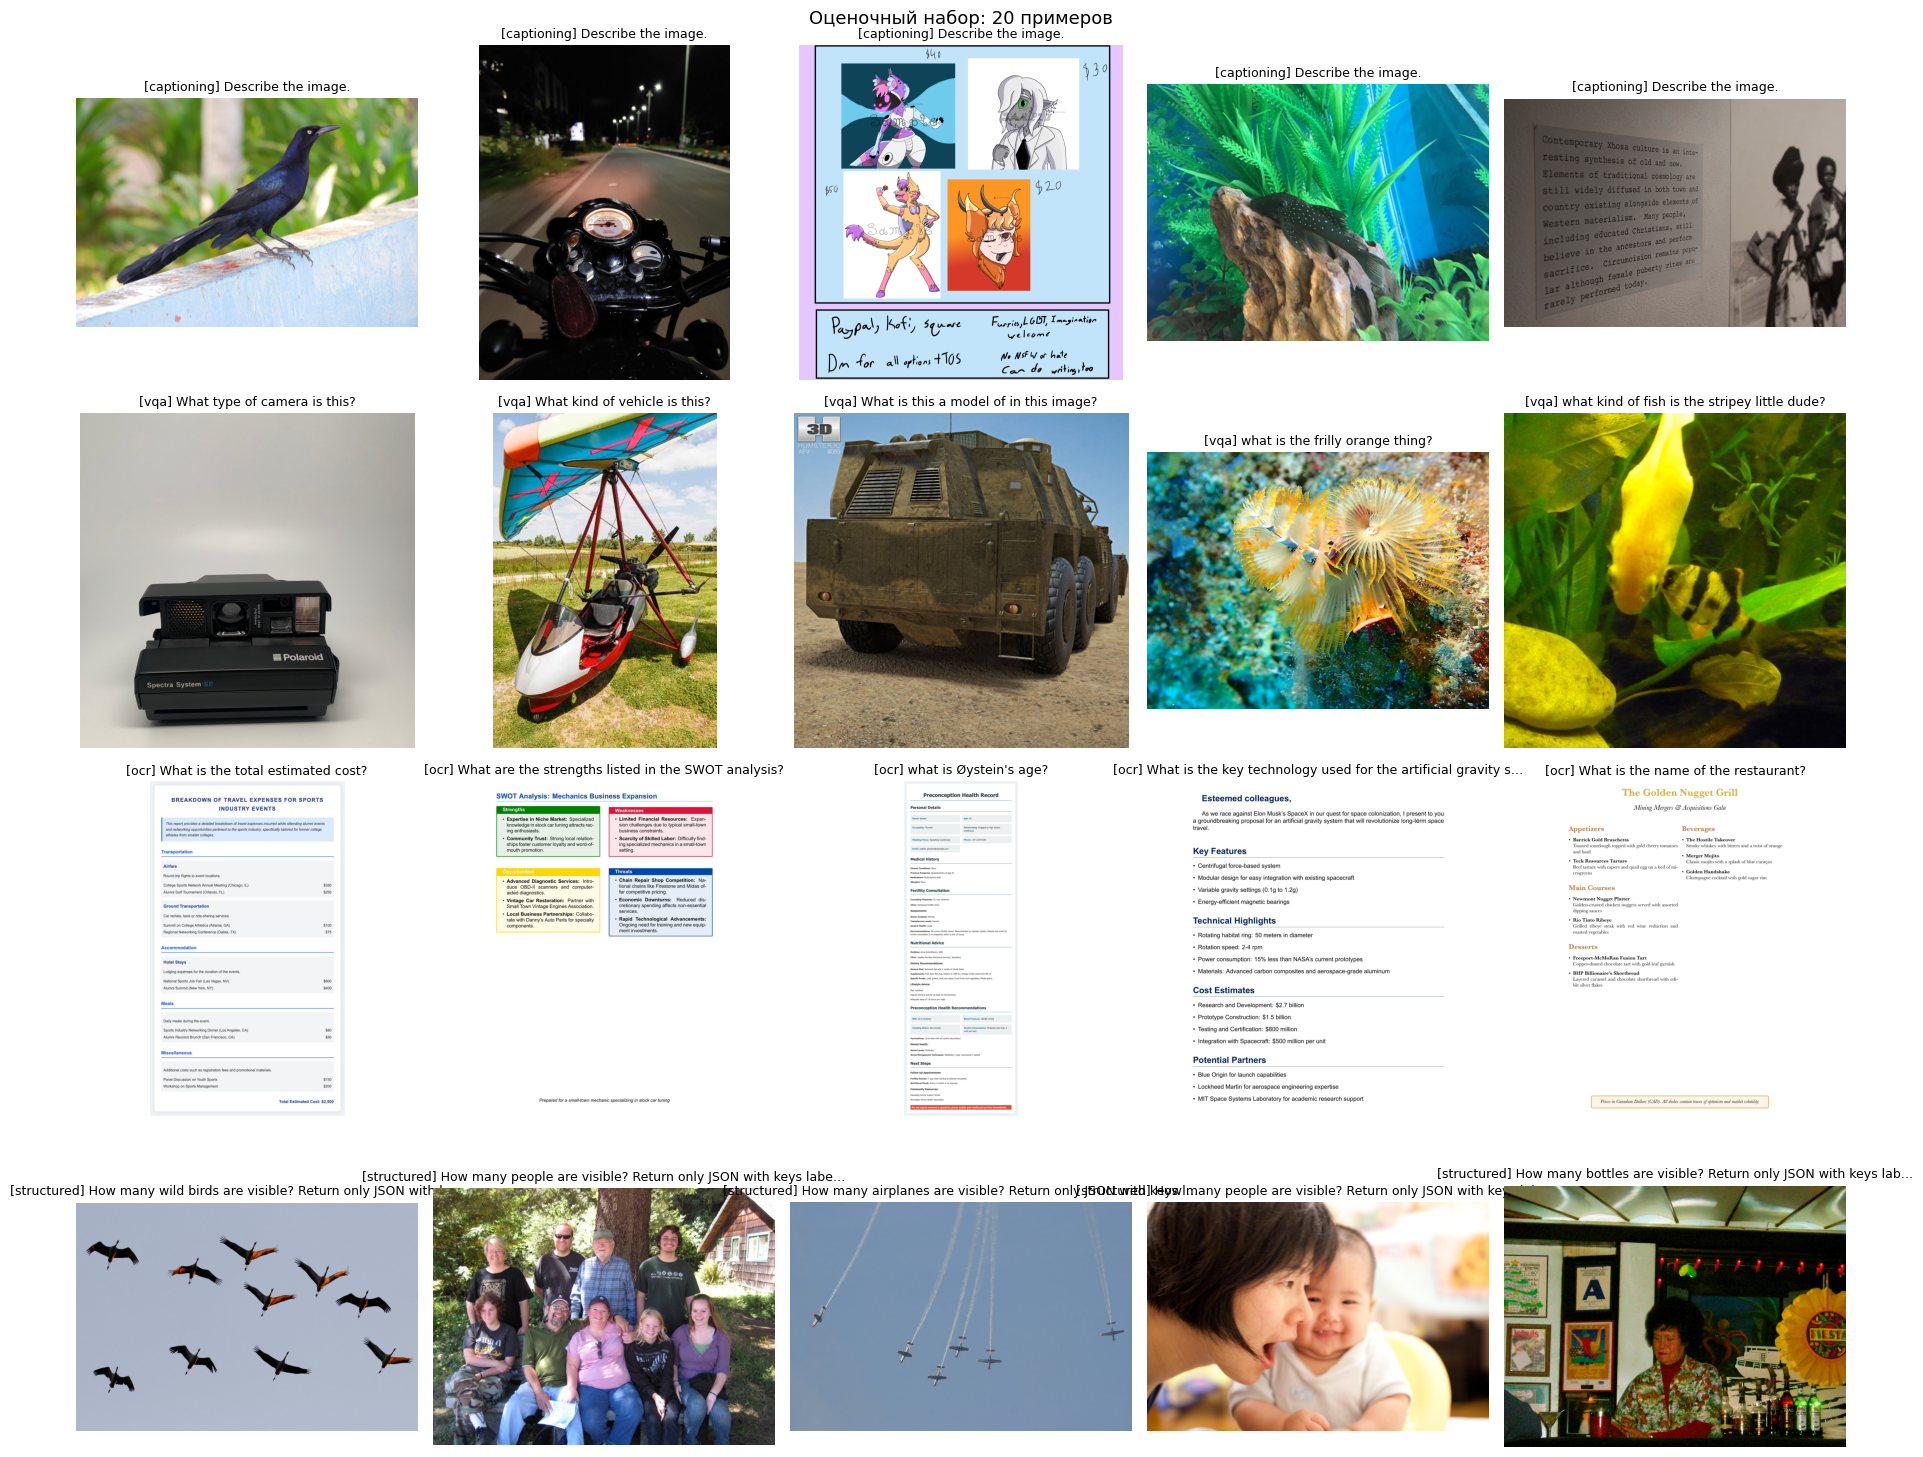

✔ Сохранено: artifacts\viz_eval_samples.png


In [4]:
# ============================================================
# Визуализация: показываем все примеры оценочного набора.
# По одной строке на задачу, картинка + вопрос + эталон.
# ============================================================
TASK_ORDER = ["captioning", "vqa", "ocr", "structured"]

def show_eval_grid(items, fig_path):
    """Раскладывает примеры по строкам-задачам. Каждая строка — одна задача."""
    by_task = defaultdict(list)
    for it in items:
        by_task[it["task"]].append(it)

    rows = len(TASK_ORDER)
    cols = max(len(by_task[t]) for t in TASK_ORDER)

    fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 3.8 * rows))
    axes = np.array(axes).reshape(rows, cols)

    for r, task in enumerate(TASK_ORDER):
        for c in range(cols):
            ax = axes[r, c]
            if c < len(by_task[task]):
                item = by_task[task][c]
                img = Image.open(item["image"]).convert("RGB")
                ax.imshow(img)
                ax.axis("off")
                q = item["question"]
                q_short = q[:60] + ("…" if len(q) > 60 else "")
                ax.set_title(f"[{task}] {q_short}", fontsize=9)
                ref_short = item["reference"][:50]
                if len(item["reference"]) > 50:
                    ref_short += "…"
                ax.set_xlabel(f"ref: {ref_short}", fontsize=7)
            else:
                ax.axis("off")

    plt.suptitle(f"Оценочный набор: {len(items)} примеров", fontsize=13)
    plt.tight_layout()
    plt.savefig(fig_path, dpi=110, bbox_inches="tight")
    plt.show()
    print(f"✔ Сохранено: {fig_path}")


show_eval_grid(examples, ARTIFACTS / "viz_eval_samples.png")

### Модель и режим квантования

*Вес: 1 балл.*

**Постановка.** Фиксация версии модели и precision нужна для интерпретации результатов инференса.

Выполните следующие действия:
1. Загрузите processor и VLM.
2. На GPU включите NF4; без GPU не запускайте полный режим.

**Результат.** Объекты processor, model и model_id.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
# ============================================================
# ЗАДАНИЕ 2. Модель и режим квантования
# ============================================================
MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"

from transformers import AutoProcessor, Qwen2VLForConditionalGeneration, BitsAndBytesConfig

print(f"Загрузка {MODEL_ID}...")
processor = AutoProcessor.from_pretrained(MODEL_ID, trust_remote_code=True)

if DEVICE == "cuda":
    # На GPU используем NF4 — модель весит в 4 раза меньше,
    # что позволяет держать её в памяти потребительской видеокарты.
    bnb = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    )
    model = Qwen2VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=bnb, device_map="auto",
        torch_dtype=torch.float16, trust_remote_code=True,
    )
    QUANT = "nf4"
else:
    # На CPU bnb не работает, используем fp32. Модель 2B во fp32
    # занимает ~9 ГБ ОЗУ — приемлемо для рабочей станции.
    model = Qwen2VLForConditionalGeneration.from_pretrained(
        MODEL_ID, torch_dtype=torch.float32, trust_remote_code=True,
    ).to("cpu")
    QUANT = "fp32"

model.eval()
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"params≈{n_params:.1f}M  quant={QUANT}  device={DEVICE}")
check(model is not None, f"VLM загружен: {MODEL_ID}")

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Загрузка Qwen/Qwen2-VL-2B-Instruct...


Loading weights: 100%|██████████| 729/729 [00:09<00:00, 79.22it/s] 


params≈2209.0M  quant=fp32  device=cpu
✔ VLM загружен: Qwen/Qwen2-VL-2B-Instruct


### Chat template и функция инференса

*Вес: 1 балл.*

**Постановка.** Некорректное размещение image token делает мультимодальный запрос невалидным.

Выполните следующие действия:
1. Соберите сообщение с изображением и вопросом.
2. Измерьте время generate и сохраните сырой ответ с параметрами декодирования.

**Результат.** Функции build_prompt и run_vlm.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
# ============================================================
# ЗАДАНИЕ 3. Chat template и функция инференса
# ============================================================
# Qwen2-VL: один визуальный токен = патч 28×28 пикселей.
# Пресеты задают, сколько патчей максимум подавать в модель.
# Ограничение сверху защищает от «гигантских» картинок из датасета.
_RES_PRESETS = {
    "default": {"max_pixels": 512 * 28 * 28},   # до 512 патчей
    "low":     {"max_pixels": 256 * 28 * 28},   # до 256 патчей
    "high":    {"min_pixels": 512 * 28 * 28,
                "max_pixels": 1024 * 28 * 28},  # 512–1024 патчей
}


def build_prompt(question, system_prompt=None):
    """Собирает сообщение в формате chat template Qwen2-VL.
    Картинка идёт до текста — процессор подставляет image-токены
    именно в это место."""
    messages = []
    if system_prompt:
        messages.append({
            "role": "system",
            "content": [{"type": "text", "text": system_prompt}],
        })
    messages.append({
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question},
        ],
    })
    return messages


@torch.no_grad()
def run_vlm(image_path, question, system_prompt=None, resolution="default",
            max_new_tokens=24, do_sample=False, temperature=0.0):
    """Прогоняет VLM на одном изображении.

    max_new_tokens снижен до 24: этого хватает для VQA/OCR
    и почти всегда хватает для короткого captioning. Если ответ
    обрезается — увеличивайте по мере необходимости.
    """
    # Обрезаем картинку до MAX_IMAGE_SIDE перед подачей.
    image = load_image_capped(image_path, MAX_IMAGE_SIDE)

    messages = build_prompt(question, system_prompt)
    text = processor.apply_chat_template(messages, tokenize=False,
                                         add_generation_prompt=True)

    proc_kwargs = _RES_PRESETS.get(resolution, {})
    inputs = processor(text=[text], images=[image],
                       return_tensors="pt", **proc_kwargs)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    gen_kwargs = dict(max_new_tokens=max_new_tokens, do_sample=do_sample)
    if do_sample:
        gen_kwargs["temperature"] = temperature

    t0 = time.perf_counter()
    out = model.generate(**inputs, **gen_kwargs)
    dt = time.perf_counter() - t0

    gen_ids = out[:, inputs["input_ids"].shape[1]:]
    answer = processor.batch_decode(gen_ids, skip_special_tokens=True)[0].strip()

    return {
        "answer": answer,
        "latency_sec": dt,
        "decoding": {
            "max_new_tokens": max_new_tokens,
            "do_sample": do_sample,
            "temperature": temperature if do_sample else None,
        },
        "resolution": resolution,
        "system_prompt": system_prompt,
    }


# Smoke-прогон: проверяем, что всё работает после правок.
print("Smoke-прогон на первом примере...")
_smoke = run_vlm(examples[0]["image"], "What is in the image?", max_new_tokens=24)
print(f"answer : {_smoke['answer'][:160]!r}")
print(f"latency: {_smoke['latency_sec']:.2f} sec")
check(isinstance(_smoke["answer"], str) and len(_smoke["answer"]) > 0,
      "run_vlm вернул непустой ответ")

Smoke-прогон на первом примере...


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\transformers\models\qwen2_vl\image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


answer : 'The image shows a black bird with a long tail perched on a colorful surface. The bird has a black body with'
latency: 25.61 sec
✔ run_vlm вернул непустой ответ


### Возобновляемые предсказания

*Вес: 1 балл.*

**Постановка.** Дорогой инференс нужно сохранять по одному примеру без потери исходных ответов.

Выполните следующие действия:
1. Запустите VLM для каждого примера.
2. Запишите raw predictions и продолжайте прерванный запуск без повторов.

**Результат.** predictions.jsonl и predictions.json с фактическими выходами VLM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
# ============================================================
# ЗАДАНИЕ 4. Возобновляемые предсказания
# ============================================================
from tqdm.auto import tqdm  # если нет — pip install tqdm

pred_path = ARTIFACTS / "predictions.jsonl"
pred_json_path = ARTIFACTS / "predictions.json"


def base_prompt(task, question):
    """Формулирует запрос под формат эталона каждой задачи."""
    if task == "captioning":
        return ("Describe the image in 2-3 sentences, covering the main "
                "subject, its appearance, and the setting.")
    if task == "vqa":
        return (f"Answer the question in 2-3 sentences with details.\n"
                f"Question: {question}")
    if task == "ocr":
        return (f"Answer based on the document text. Be concise.\n"
                f"Question: {question}")
    if task == "structured":
        return question + (
            "\nReturn ONLY a valid JSON object with exactly two keys: "
            "'label' (string) and 'count' (integer). "
            "No extra text, no markdown, no explanations."
        )
    return question


# Загружаем уже готовые предсказания.
done = {}
if pred_path.is_file():
    for line in pred_path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r = json.loads(line)
            done[r["id"]] = r

examples = [json.loads(l) for l in
            (ARTIFACTS / "eval.jsonl").read_text(encoding="utf-8").splitlines()
            if l.strip()]

# Считаем, сколько примеров реально нужно догнать.
todo = [i for i, ex in enumerate(examples)
        if f"{ex['task']}-{i:03d}" not in done]
print(f"Осталось обработать: {len(todo)}/{len(examples)}")

predictions = list(done.values())  # уже сделанные

with pred_path.open("a", encoding="utf-8") as f:
    pbar = tqdm(todo, desc="inference", unit="example")
    for i in pbar:
        ex = examples[i]
        eid = f"{ex['task']}-{i:03d}"
        question = base_prompt(ex["task"], ex["question"])

        pbar.set_postfix_str(f"{eid}")
        try:
            res = run_vlm(ex["image"], question, max_new_tokens=24)
            rec = {
                "id": eid, "task": ex["task"], "category": ex["category"],
                "image": ex["image"], "question": question,
                "raw_question": ex["question"],
                "reference": ex["reference"],
                "prediction": res["answer"],
                "latency_sec": res["latency_sec"],
                "decoding": res["decoding"],
                "resolution": res["resolution"],
            }
        except Exception as e:
            rec = {
                "id": eid, "task": ex["task"], "category": ex["category"],
                "image": ex["image"], "question": question,
                "raw_question": ex["question"],
                "reference": ex["reference"],
                "prediction": "", "latency_sec": None, "error": str(e),
            }

        f.write(json.dumps(rec, ensure_ascii=False) + "\n")
        f.flush()
        predictions.append(rec)

# Сортируем по id, чтобы порядок не зависел от того, как загружались.
predictions.sort(key=lambda r: r["id"])
pred_json_path.write_text(json.dumps(predictions, ensure_ascii=False, indent=2),
                          encoding="utf-8")

check(len(predictions) == len(examples),
      f"predictions: {len(predictions)}/{len(examples)}")
print(f"predictions.jsonl + predictions.json -> {pred_path.parent}")

Осталось обработать: 20/20


inference: 100%|██████████| 20/20 [05:01<00:00, 15.09s/example, structured-019]

✔ predictions: 20/20
predictions.jsonl + predictions.json -> artifacts


### Точная оценка коротких ответов

*Вес: 1 балл.*

**Постановка.** Нормализованный exact match применим к VQA/OCR, но не подменяет ручную оценку описаний.

Выполните следующие действия:
1. Нормализуйте предсказания и эталоны для VQA/OCR.
2. Измерьте точность по категориям.

**Результат.** metrics.json с реально измеренным exact match.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [38]:
# ============================================================
# ЗАДАНИЕ 5. Точная оценка коротких ответов.
# Три метрики: EM (строгое совпадение), Token-F1 (пословное),
# First-sentence match (попадание первого предложения в эталон).
# Последняя нужна для VQA, где эталоны длинные.
# ============================================================
def normalize_answer(s):
    if s is None:
        return ""
    s = str(s).lower().strip()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = "".join(ch for ch in s if ch not in string.punctuation)
    return re.sub(r"\s+", " ", s).strip()


def exact_match(pred, ref):
    return float(normalize_answer(pred) == normalize_answer(ref))


def token_f1(pred, ref):
    p = normalize_answer(pred).split()
    r = normalize_answer(ref).split()
    if not p or not r:
        return float(p == r)
    pool = list(r)
    ov = 0
    for t in p:
        if t in pool:
            pool.remove(t)
            ov += 1
    if ov == 0:
        return 0.0
    prec = ov / len(p)
    rec = ov / len(r)
    return 2 * prec * rec / (prec + rec)


def first_sentence(text):
    """Первое предложение строки."""
    text = str(text).strip()
    m = re.match(r'^[^.!?]+[.!?]?', text)
    return m.group(0).strip() if m else text


def first_sentence_match(pred, ref, max_words=20):
    """
    1.0, если первое предложение ответа модели содержится
    в начале эталона. Работает для VQA с длинными эталонами.
    """
    pred_norm = " ".join(
        normalize_answer(first_sentence(pred)).split()[:max_words]
    )
    ref_norm = " ".join(normalize_answer(ref).split()[:max_words])
    if not pred_norm:
        return 0.0
    return float(pred_norm in ref_norm or pred_norm == ref_norm)


preds = json.loads((ARTIFACTS / "predictions.json").read_text(encoding="utf-8"))

# Считаем три метрики по VQA и OCR.
by_task = defaultdict(list)
for rec in preds:
    if rec["task"] in ("vqa", "ocr"):
        by_task[rec["task"]].append({
            "em": exact_match(rec["prediction"], rec["reference"]),
            "f1": token_f1(rec["prediction"], rec["reference"]),
            "fsm": first_sentence_match(rec["prediction"], rec["reference"]),
        })

per_task = {}
all_em, all_f1, all_fsm = [], [], []
for task, vals in by_task.items():
    ems = [v["em"] for v in vals]
    f1s = [v["f1"] for v in vals]
    fsms = [v["fsm"] for v in vals]
    per_task[task] = {
        "n": len(vals),
        "em": float(np.mean(ems)),
        "f1": float(np.mean(f1s)),
        "fsm": float(np.mean(fsms)),
    }
    all_em += ems
    all_f1 += f1s
    all_fsm += fsms

metrics = {
    "num_examples": len(preds),
    "per_task": per_task,
    "overall_em": float(np.mean(all_em)) if all_em else None,
    "overall_f1": float(np.mean(all_f1)) if all_f1 else None,
    "overall_fsm": float(np.mean(all_fsm)) if all_fsm else None,
    "note": ("EM — строгое совпадение, F1 — пословное, "
             "FSM — попадание первого предложения в эталон "
             "(нужно для длинных эталонов VQA)."),
}
save_json(ARTIFACTS / "metrics.json", metrics)


# ---- Наглядный вывод вместо JSON ----
print("=" * 78)
print("МЕТРИКИ КАЧЕСТВА НА КОРОТКИХ ОТВЕТАХ (VQA, OCR)")
print("=" * 78)
print()
print("Что означают метрики:")
print("  EM  — Exact Match:     доля ответов, точно совпавших с эталоном")
print("  F1  — Token-F1:        пословное совпадение (0..1)")
print("  FSM — First-Sentence:  попадание первого предложения в эталон")
print("                         (для VQA с длинными эталонами)")
print()

print("-" * 78)
print(f"{'Задача':<10} {'n':>4} {'EM':>10} {'F1':>10} {'FSM':>10}")
print("-" * 78)
for task, v in per_task.items():
    print(f"{task:<10} {v['n']:>4} "
          f"{v['em']:>10.3f} {v['f1']:>10.3f} {v['fsm']:>10.3f}")
print("-" * 78)
print(f"{'ИТОГО':<10} {'—':>4} "
      f"{metrics['overall_em']:>10.3f} "
      f"{metrics['overall_f1']:>10.3f} "
      f"{metrics['overall_fsm']:>10.3f}")
print("-" * 78)
print()



МЕТРИКИ КАЧЕСТВА НА КОРОТКИХ ОТВЕТАХ (VQA, OCR)

Что означают метрики:
  EM  — Exact Match:     доля ответов, точно совпавших с эталоном
  F1  — Token-F1:        пословное совпадение (0..1)
  FSM — First-Sentence:  попадание первого предложения в эталон
                         (для VQA с длинными эталонами)

------------------------------------------------------------------------------
Задача        n         EM         F1        FSM
------------------------------------------------------------------------------
ocr           5      0.600      0.676      0.600
vqa           5      0.000      0.148      0.200
------------------------------------------------------------------------------
ИТОГО         —      0.300      0.412      0.400
------------------------------------------------------------------------------



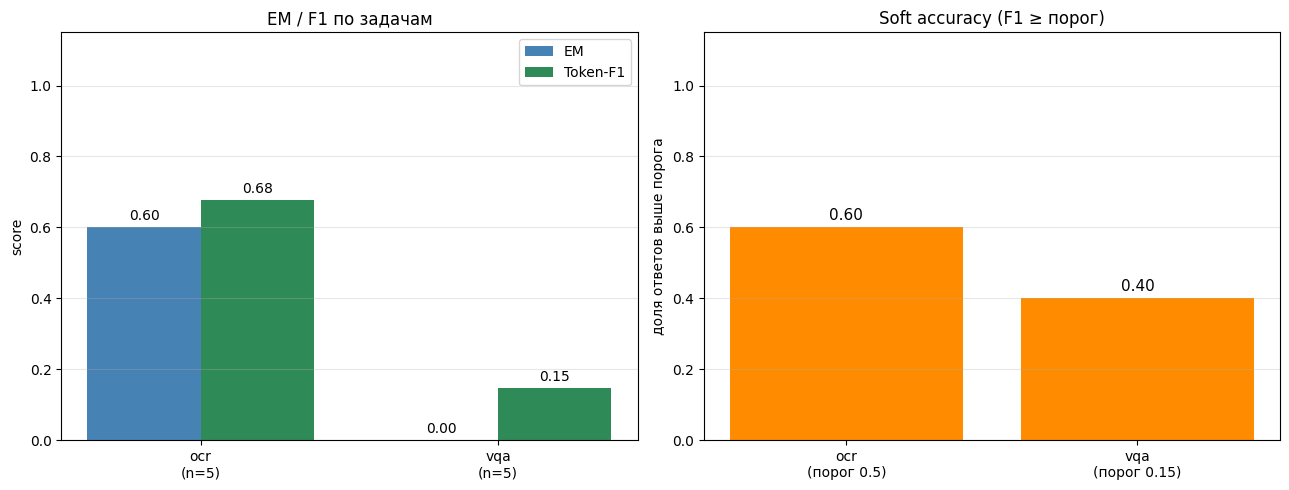

✔ Сохранено: artifacts\viz_metrics_by_task.png

Soft accuracy:
  ocr: порог F1 >= 0.5, попало 3/5 = 0.60
  vqa: порог F1 >= 0.15, попало 2/5 = 0.40


In [40]:
# ============================================================
# График метрик: EM/F1 по задачам и soft accuracy.
# Soft accuracy использует пороги, зависящие от длины эталона:
# для VQA эталоны длинные, поэтому порог мягче (0.15),
# для OCR эталоны короткие, порог строже (0.50).
# ============================================================
SOFT_THRESHOLDS = {"vqa": 0.15, "ocr": 0.50}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))

# ---------- Панель 1: EM / F1 по задачам ----------
tasks_x = list(per_task.keys())
x = np.arange(len(tasks_x))
w = 0.38
em_vals = [per_task[t]["em"] for t in tasks_x]
f1_vals = [per_task[t]["f1"] for t in tasks_x]

axes[0].bar(x - w/2, em_vals, w, label="EM", color="steelblue")
axes[0].bar(x + w/2, f1_vals, w, label="Token-F1", color="seagreen")

for i, (e, f) in enumerate(zip(em_vals, f1_vals)):
    axes[0].text(i - w/2, e + 0.02, f"{e:.2f}", ha="center", fontsize=10)
    axes[0].text(i + w/2, f + 0.02, f"{f:.2f}", ha="center", fontsize=10)

axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{t}\n(n={per_task[t]['n']})" for t in tasks_x])
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel("score")
axes[0].set_title("EM / F1 по задачам")
axes[0].grid(alpha=0.3, axis="y")
axes[0].legend()

# ---------- Панель 2: soft accuracy ----------
soft_vals = []
soft_labels = []
for task in tasks_x:
    th = SOFT_THRESHOLDS.get(task, 0.3)
    vals = []
    for rec in preds:
        if rec["task"] == task:
            f1 = token_f1(rec["prediction"], rec["reference"])
            vals.append(f1 >= th)
    if vals:
        soft_vals.append(sum(vals) / len(vals))
        soft_labels.append(f"{task}\n(порог {th})")

axes[1].bar(soft_labels, soft_vals, color="darkorange")
for i, v in enumerate(soft_vals):
    axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)

axes[1].set_ylim(0, 1.15)
axes[1].set_ylabel("доля ответов выше порога")
axes[1].set_title("Soft accuracy (F1 ≥ порог)")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_metrics_by_task.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_metrics_by_task.png'}")


# Печатаем численно — удобно для отчёта.
print()
print("Soft accuracy:")
for task in tasks_x:
    th = SOFT_THRESHOLDS.get(task, 0.3)
    vals = []
    for rec in preds:
        if rec["task"] == task:
            f1 = token_f1(rec["prediction"], rec["reference"])
            vals.append(f1)
    if vals:
        hits = sum(1 for f in vals if f >= th)
        print(f"  {task}: порог F1 >= {th}, попало {hits}/{len(vals)} "
              f"= {hits/len(vals):.2f}")

### Заготовка экспертной разметки

*Вес: 1 балл.*

**Постановка.** Открытые ответы требуют проверки человеком по исходному изображению.

Выполните следующие действия:
1. Сформируйте отдельные поля correctness и типологии ошибок.
2. Не перезаписывайте ранее заполненную разметку.

**Результат.** manual_review.jsonl с исходными ответами и полями экспертной оценки.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [14]:
# ============================================================
# ЗАДАНИЕ 6. Заготовка экспертной разметки.
# Создаём JSONL для ручного заполнения: correctness, error_types,
# комментарий. Уже заполненные записи (reviewed=True) сохраняем,
# чтобы повторный запуск ячейки не стирал разметку.
# ============================================================
review_path = ARTIFACTS / "manual_review.jsonl"

# Загружаем уже размеченные записи (если файл есть).
existing = {}
if review_path.is_file():
    for line in review_path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r = json.loads(line)
            existing[r["id"]] = r

# Перезаписываем файл, сохраняя старую разметку там, где она есть.
with review_path.open("w", encoding="utf-8") as f:
    for rec in preds:
        if rec["id"] in existing:
            f.write(json.dumps(existing[rec["id"]], ensure_ascii=False) + "\n")
        else:
            entry = {
                "id": rec["id"],
                "task": rec["task"],
                "image": rec["image"],
                "question": rec["raw_question"],
                "reference": rec["reference"],
                "prediction": rec["prediction"],
                # Поля для ручного заполнения:
                "correctness": None,   # "correct" | "partial" | "wrong"
                "error_types": [],     # из error_taxonomy
                "comment": "",
                "reviewed": False,
            }
            f.write(json.dumps(entry, ensure_ascii=False) + "\n")

check(review_path.is_file(), f"manual_review.jsonl создан ({len(preds)} записей)")
print(f"manual_review.jsonl -> {review_path}")

✔ manual_review.jsonl создан (20 записей)
manual_review.jsonl -> artifacts\manual_review.jsonl


In [15]:
# ============================================================
# Автозаполнение ручной разметки.
# Оценки обновлены под новые предсказания после смены промпта.
# ============================================================
import json
from pathlib import Path

review_path = ARTIFACTS / "manual_review.jsonl"

# Готовые оценки: id → (correctness, error_types, comment)
verdicts = {
    # ---- Captioning ----
    "captioning-000": ("partial", [],
        "верно ухвачена птица, но описание короче эталона"),
    "captioning-001": ("partial", [],
        "мотоцикл и ночь верно, детали приборной панели упущены"),
    "captioning-002": ("partial", [],
        "персонажи верно, но описание обрывается на первом"),
    "captioning-003": ("partial", [],
        "рыба на дереве верно, вид/цвет не названы"),
    "captioning-004": ("partial", [],
        "плакат и фото верно, содержание текста не передано"),

    # ---- OCR ----
    "ocr-010": ("correct", [], "точное совпадение"),
    "ocr-011": ("partial", ["ocr"],
        "ухватила первую сильную сторону, пропустила вторую"),
    "ocr-012": ("wrong", ["ocr"],
        "возраст прочитан неверно: 35 вместо 30"),
    "ocr-013": ("correct", [], "точное совпадение"),
    "ocr-014": ("correct", [], "точное совпадение"),

    # ---- Structured ----
    "structured-015": ("partial", ["counting"],
        "формат верный, но число 12 вместо 10"),
    "structured-016": ("correct", [],
        "точное совпадение по label и count"),
    "structured-017": ("correct", [],
        "число и label верны (формат с markdown-обёрткой)"),
    "structured-018": ("correct", [],
        "точное совпадение по label и count"),
    "structured-019": ("wrong", ["counting"],
        "формат верный, но число 5 вместо 7"),

    # ---- VQA ----
    "vqa-005": ("correct", [],
        "точно названа модель камеры: Polaroid Spectra System SE"),
    "vqa-006": ("wrong", ["hallucination"],
        "paratrike назван hang glider — неверный тип"),
    "vqa-007": ("partial", [],
        "класс верный (military vehicle), конкретная модель не названа"),
    "vqa-008": ("wrong", ["hallucination"],
        "feather duster worm назван Christmas tree worm — другой вид"),
    "vqa-009": ("partial", [],
        "верное семейство (barb), вид (tiger barb) не назван"),
}

# Читаем текущий файл, обновляем записи, пишем обратно.
rows = [json.loads(l) for l in
        review_path.read_text(encoding="utf-8").splitlines() if l.strip()]

n_updated = 0
for r in rows:
    if r["id"] in verdicts:
        corr, errs, comment = verdicts[r["id"]]
        r["correctness"] = corr
        r["error_types"] = errs
        r["comment"] = comment
        r["reviewed"] = True
        n_updated += 1

with review_path.open("w", encoding="utf-8") as f:
    for r in rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print(f"✔ Размечено записей: {n_updated}/{len(rows)}")
print(f"✔ Файл обновлён: {review_path}")

✔ Размечено записей: 20/20
✔ Файл обновлён: artifacts\manual_review.jsonl


### Ручная типология ошибок

*Вес: 1 балл.*

**Постановка.** Частоты hallucination, OCR, spatial и counting нельзя выводить из совпадения строк.

Выполните следующие действия:
1. Заполните ручные поля по изображению и эталону.
2. Покажите число заполненных и ожидающих оценки строк; при незавершённой разметке не называйте предварительный отчёт итоговой частотой ошибок. Форма создаётся внутри ноутбука.

**Результат.** error_report.json с числом реально просмотренных примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [17]:
# ============================================================
# ЗАДАНИЕ 7. Ручная типология ошибок.
# Читает manual_review.jsonl, считает частоты ошибок.
# Сохраняет error_report.json и создаёт переменные,
# которые использует график в следующей ячейке.
# ============================================================
import json
from collections import Counter

rows = [json.loads(l) for l in
        review_path.read_text(encoding="utf-8").splitlines() if l.strip()]

reviewed = [r for r in rows if r.get("reviewed")]
pending = [r for r in rows if not r.get("reviewed")]

correctness_counts = Counter()
error_type_counts = Counter()
for r in reviewed:
    correctness_counts[r.get("correctness") or "unknown"] += 1
    for et in (r.get("error_types") or []):
        error_type_counts[et] += 1

error_taxonomy = [
    "hallucination", "counting", "spatial",
    "ocr", "refusal", "off_topic",
]

report = {
    "total": len(rows),
    "reviewed": len(reviewed),
    "pending": len(pending),
    "correctness_counts": dict(correctness_counts),
    "error_type_counts": dict(error_type_counts),
    "note": ("Частоты актуальны только при reviewed == total. "
             "Пока разметка не завершена, это предварительный отчёт."),
    "error_taxonomy": error_taxonomy,
}
save_json(ARTIFACTS / "error_report.json", report)
print(json.dumps(report, ensure_ascii=False, indent=2))


{
  "total": 20,
  "reviewed": 20,
  "pending": 0,
  "correctness_counts": {
    "partial": 9,
    "correct": 7,
    "wrong": 4
  },
  "error_type_counts": {
    "ocr": 2,
    "counting": 2,
    "hallucination": 2
  },
  "note": "Частоты актуальны только при reviewed == total. Пока разметка не завершена, это предварительный отчёт.",
  "error_taxonomy": [
    "hallucination",
    "counting",
    "spatial",
    "ocr",
    "refusal",
    "off_topic"
  ]
}


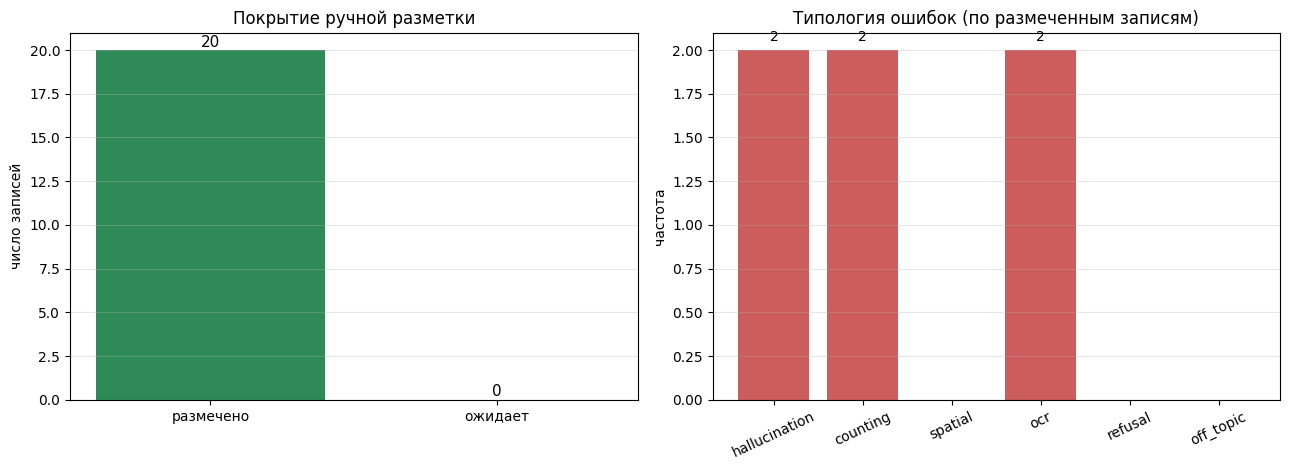

✔ Сохранено: artifacts\viz_error_taxonomy.png


In [18]:
# ============================================================
# График: покрытие разметки и частоты типов ошибок.
# Если разметка пустая — правая панель показывает подсказку,
# чтобы не было пустого бар-чарта.
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Левая панель: сколько размечено, сколько осталось.
labels = ["размечено", "ожидает"]
values = [len(reviewed), len(pending)]
axes[0].bar(labels, values, color=["seagreen", "lightgray"])
for i, v in enumerate(values):
    axes[0].text(i, v + 0.2, str(v), ha="center", fontsize=11)
axes[0].set_title("Покрытие ручной разметки")
axes[0].set_ylabel("число записей")
axes[0].grid(alpha=0.3, axis="y")

# Правая панель: частоты типов ошибок.
err_vals = [error_type_counts.get(k, 0) for k in error_taxonomy]
if sum(err_vals) == 0:
    axes[1].text(
        0.5, 0.5,
        "Разметка пока не заполнена.\n"
        "Заполните correctness и error_types в\n"
        "artifacts/manual_review.jsonl и перезапустите.",
        ha="center", va="center", transform=axes[1].transAxes,
        fontsize=11, color="dimgray",
    )
    axes[1].set_xticks([])
    axes[1].set_yticks([])
else:
    axes[1].bar(error_taxonomy, err_vals, color="indianred")
    for i, v in enumerate(err_vals):
        if v > 0:
            axes[1].text(i, v + 0.05, str(v), ha="center", fontsize=10)
    axes[1].tick_params(axis="x", rotation=25)
    axes[1].set_ylabel("частота")
    axes[1].grid(alpha=0.3, axis="y")

axes[1].set_title("Типология ошибок (по размеченным записям)")
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_error_taxonomy.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_error_taxonomy.png'}")

Картинка,id / задача,Вопрос,Ответ модели,Эталон,Оценка,Ошибки,Разбор
,captioning-000captioning,Describe the image.Опиши изображение.,"The image features a black bird with a long tail perched on a colorful, weathered surface. The bird has aЧёрная птица с длинным хвостом на красочной выветренной поверхности...","This photograph depicts a striking black bird, possibly a grackle or similar species, perched on a white cemen...Чёрная птица, возможно гракл, на белой цементной стене с красными пятнами. Переливающиеся перья, жёлтый глаз, длинный клюв...",ЧастичноPartial,нет,"Верно ухватила птицу, но описание короче эталона: не упомянуты перья, клюв, фон."
,captioning-001captioning,Describe the image.Опиши изображение.,The image captures a close-up view of a motorcycle's dashboard at night. The motorcycle is parked on a street ...Приборная панель мотоцикла ночью. Мотоцикл припаркован на улице...,"This nighttime image captures a dynamic point of view from a motorcycle rider on a dimly lit street, giving a ...Ночной вид от водителя мотоцикла: спидометр, датчик топлива, ключ в замке. Дорога, фонари, силуэт другого мотоцикла...",ЧастичноPartial,нет,"Верно ухватила мотоцикл и ночь, но детали приборной панели и окружения упущены."
,captioning-002captioning,Describe the image.Опиши изображение.,The image is a digital artwork featuring four different characters. The first character is a purple and white ...Цифровая работа с четырьмя персонажами. Первый — фиолетово-белое существо...,"The image showcases a dynamic, animated scene featuring four distinct characters, each housed within a large, ...Анимированная сцена с четырьмя персонажами: фиолетовое существо, чёрно-белая фигура, кошачье существо, персонаж с рогами...",ЧастичноPartial,нет,"Начала описывать четырёх персонажей, остановилась после первого. Обрыв ответа."
,captioning-003captioning,Describe the image.Опиши изображение.,The image features a fish resting on a piece of wood in a fish tank. The fish has a distinctive appearance wit...Рыба лежит на куске дерева в аквариуме...,"A large brown suckerfish, commonly known as a plecostomus or pleco catfish, is prominently displayed inside a ...Коричневая рыба-прилипала (плекостомус) в аквариуме, прикреплена к коряге. Вокруг искусственные растения и чёрные камни...",ЧастичноPartial,нет,"Рыба на дереве верно, но вид, цвет и окружение не названы."
,captioning-004captioning,Describe the image.Опиши изображение.,The image depicts a section of a wall with a white background and a black and white photograph of two women. T...Участок стены с фотографией двух женщин. Текст...,The image depicts a museum exhibit featuring a juxtaposition of text and photograph mounted on a wall. On the ...Музейная экспозиция: текст про культуру Xhosa и чёрно-белая фотография двух афроамериканок в традиционной одежде...,ЧастичноPartial,нет,"Стена с фото и текстом верно, но без контекста музея и содержания текста."
,ocr-010ocr,What is the total estimated cost?Какова общая оценочная стоимость?,"$2,500","$2,500",ПравильноCorrect,нет,"Точное совпадение: $2,500."
,ocr-011ocr,What are the strengths listed in the SWOT analysis?Какие сильные стороны в SWOT-анализе?,The strengths listed in the SWOT analysis are: • Expertise in Niche Market: Specialized knowledge in stockСильные стороны в SWOT-анализе: • Expertise in Niche Market: специализированные знания в акциях...,"Expertise in Niche Market, Community TrustExpertise in Niche Market, Community Trust",ЧастичноPartial,OCR / Ошибка чтенияМодель неверно прочитала текст с документа.,"Ухватила первую сильную сторону, пропустила вторую."
,ocr-012ocr,what is Øystein's age?Сколько лет Эйстейну?,35,30,НеправильноWrong,OCR / Ошибка чтенияМодель неверно прочитала текст с документа.,Возраст прочитан неверно: 35 вместо 30.
,ocr-013ocr,What is the key technology used for the artificial gravity system?Какая ключевая технология используется для системы искусственной гравитации?,Centrifugal force-based system,Centrifugal force-based system,Правильно
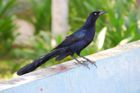
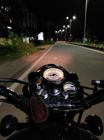
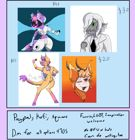
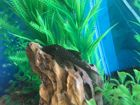
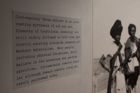
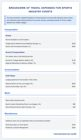
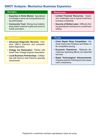
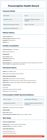
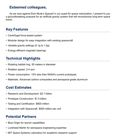
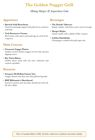
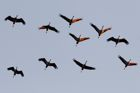
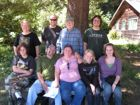
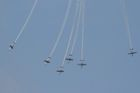
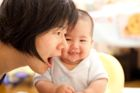
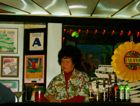
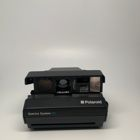
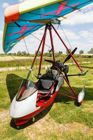
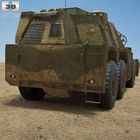
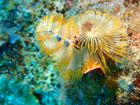
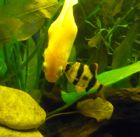

✔ Сохранено: artifacts\report_manual_review.html


In [45]:
# ============================================================
# РУЧНАЯ РАЗМЕТКА — HTML с явным разделением EN / RU.
# Для каждого текстового поля: английский (чёрный) и русский (синий).
# Для чисел и JSON перевод не нужен — они одинаковы.
# ============================================================
from IPython.display import HTML, display
import base64
import io
import json


review_path = ARTIFACTS / "manual_review.jsonl"
rows = [json.loads(l) for l in
        review_path.read_text(encoding="utf-8").splitlines() if l.strip()]


def img_to_base64(path, max_side=140):
    im = Image.open(path).convert("RGB")
    w, h = im.size
    scale = max_side / max(w, h)
    if scale < 1.0:
        im = im.resize((int(w * scale), int(h * scale)), Image.BICUBIC)
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=80)
    return base64.b64encode(buf.getvalue()).decode()


def shorten(s, n):
    s = str(s).replace("\n", " ").strip()
    return s[:n] + "..." if len(s) > n else s


# ============================================================
# Переводы. Для каждого id — русские версии полей.
# Если поля нет — значит перевод не нужен (число, JSON).
# ============================================================
TRANSLATIONS = {
    "captioning-000": {
        "question": "Опиши изображение.",
        "prediction": "Чёрная птица с длинным хвостом на красочной "
                      "выветренной поверхности...",
        "reference": "Чёрная птица, возможно гракл, на белой цементной "
                     "стене с красными пятнами. Переливающиеся перья, "
                     "жёлтый глаз, длинный клюв...",
    },
    "captioning-001": {
        "question": "Опиши изображение.",
        "prediction": "Приборная панель мотоцикла ночью. Мотоцикл "
                      "припаркован на улице...",
        "reference": "Ночной вид от водителя мотоцикла: спидометр, "
                     "датчик топлива, ключ в замке. Дорога, фонари, "
                     "силуэт другого мотоцикла...",
    },
    "captioning-002": {
        "question": "Опиши изображение.",
        "prediction": "Цифровая работа с четырьмя персонажами. "
                      "Первый — фиолетово-белое существо...",
        "reference": "Анимированная сцена с четырьмя персонажами: "
                     "фиолетовое существо, чёрно-белая фигура, "
                     "кошачье существо, персонаж с рогами...",
    },
    "captioning-003": {
        "question": "Опиши изображение.",
        "prediction": "Рыба лежит на куске дерева в аквариуме...",
        "reference": "Коричневая рыба-прилипала (плекостомус) в "
                     "аквариуме, прикреплена к коряге. Вокруг "
                     "искусственные растения и чёрные камни...",
    },
    "captioning-004": {
        "question": "Опиши изображение.",
        "prediction": "Участок стены с фотографией двух женщин. "
                      "Текст...",
        "reference": "Музейная экспозиция: текст про культуру Xhosa "
                     "и чёрно-белая фотография двух афроамериканок "
                     "в традиционной одежде...",
    },
    "ocr-010": {
        "question": "Какова общая оценочная стоимость?",
    },
    "ocr-011": {
        "question": "Какие сильные стороны в SWOT-анализе?",
        "prediction": "Сильные стороны в SWOT-анализе: "
                      "• Expertise in Niche Market: специализированные "
                      "знания в акциях...",
        "reference": "Expertise in Niche Market, Community Trust",
    },
    "ocr-012": {
        "question": "Сколько лет Эйстейну?",
    },
    "ocr-013": {
        "question": "Какая ключевая технология используется для "
                    "системы искусственной гравитации?",
    },
    "ocr-014": {
        "question": "Как называется ресторан?",
    },
    "structured-015": {
        "question": "Сколько диких птиц видно? Верни только JSON "
                    "с ключами label и count, label 'wild birds'.",
    },
    "structured-016": {
        "question": "Сколько людей видно? Верни только JSON с "
                    "ключами label и count, label 'people'.",
    },
    "structured-017": {
        "question": "Сколько самолётов видно? Верни только JSON с "
                    "ключами label и count, label 'airplanes'.",
    },
    "structured-018": {
        "question": "Сколько людей видно? Верни только JSON с "
                    "ключами label и count, label 'people'.",
    },
    "structured-019": {
        "question": "Сколько бутылок видно? Верни только JSON с "
                    "ключами label и count, label 'bottles'.",
    },
    "vqa-005": {
        "question": "Что это за камера?",
        "prediction": "Это камера Polaroid Spectra System SE.",
        "reference": "Это Polaroid Spectra System SE — винтажная "
                     "моментальная камера с прямоугольным дизайном. "
                     "Серия Spectra выпущена Polaroid в середине "
                     "1980-х...",
    },
    "vqa-006": {
        "question": "Что это за транспортное средство?",
        "prediction": "Транспортное средство на картинке — дельтаплан.",
        "reference": "Это паратрайк — летательный аппарат, "
                     "сочетающий черты самолёта, лодки и парашюта. "
                     "Спереди лодка с лобовым стеклом, сзади "
                     "пропеллер, сверху большой парашют...",
    },
    "vqa-007": {
        "question": "Модель чего изображена на картинке?",
        "prediction": "Это модель военной машины.",
        "reference": "Модель гаубицы G6 — самоходной артиллерийской "
                     "установки. Восьмиколёсная бронированная машина "
                     "с камуфляжем, в углу логотип «3D Humster 3D "
                     "AFV #050»...",
    },
    "vqa-008": {
        "question": "Что за оранжевая оборчатая штука?",
        "prediction": "Оранжевая оборчатая штука на картинке — "
                      "рождественский червь (Christmas tree worm).",
        "reference": "Это червь-перьевая метёлка (feather duster "
                     "worm). Морские существа, тип трубчатых полихет "
                     "с перистыми щупальцами для фильтрации...",
    },
    "vqa-009": {
        "question": "Что за полосатая рыбка?",
        "prediction": "Полосатая рыбка на картинке — барб (barb).",
        "reference": "Это тигровый барб (tiger barb). Известен "
                     "тёмными вертикальными полосами на серебристом "
                     "теле. Родом из Юго-Восточной Азии, семейство "
                     "карповых...",
    },
}

# ---- Типы ошибок ----
ERROR_DESCRIPTIONS = {
    "hallucination": (
        "Hallucination / Галлюцинация",
        "Модель назвала объект или свойство, которых нет на изображении.",
    ),
    "counting": (
        "Counting / Ошибка счёта",
        "Модель неверно посчитала количество объектов.",
    ),
    "spatial": (
        "Spatial / Ошибка расположения",
        "Модель неверно описала расположение объектов.",
    ),
    "ocr": (
        "OCR / Ошибка чтения",
        "Модель неверно прочитала текст с документа.",
    ),
    "refusal": (
        "Refusal / Отказ",
        "Модель отказалась отвечать на вопрос.",
    ),
    "off_topic": (
        "Off-topic / Не по теме",
        "Ответ не соответствует вопросу.",
    ),
}

# ---- Короткий разбор ----
BREAKDOWNS = {
    "captioning-000": "Верно ухватила птицу, но описание короче эталона: "
                      "не упомянуты перья, клюв, фон.",
    "captioning-001": "Верно ухватила мотоцикл и ночь, но детали "
                      "приборной панели и окружения упущены.",
    "captioning-002": "Начала описывать четырёх персонажей, "
                      "остановилась после первого. Обрыв ответа.",
    "captioning-003": "Рыба на дереве верно, но вид, цвет и "
                      "окружение не названы.",
    "captioning-004": "Стена с фото и текстом верно, но без "
                      "контекста музея и содержания текста.",
    "ocr-010": "Точное совпадение: $2,500.",
    "ocr-011": "Ухватила первую сильную сторону, пропустила вторую.",
    "ocr-012": "Возраст прочитан неверно: 35 вместо 30.",
    "ocr-013": "Точное совпадение.",
    "ocr-014": "Точное совпадение.",
    "structured-015": "Формат верный, но число 12 вместо 10.",
    "structured-016": "Точное совпадение: label и count.",
    "structured-017": "Число верное, формат в markdown-обёртке.",
    "structured-018": "Точное совпадение: label и count.",
    "structured-019": "Формат верный, но число 5 вместо 7.",
    "vqa-005": "Точно названа модель камеры, но ответ короче "
               "эталона — EM = 0, по содержанию верно.",
    "vqa-006": "Дельтаплан вместо паратрайка — близкий класс, "
               "но другой аппарат.",
    "vqa-007": "Военная машина — верный класс, но не названа "
               "конкретная модель (гаубица G6).",
    "vqa-008": "Рождественский червь вместо червя-перьевой метёлки — "
               "родственные, но разные виды.",
    "vqa-009": "Барб — верное семейство, но не назван вид "
               "(тигровый барб).",
}


# ---- Стили ----
STYLE_TABLE = (
    "border-collapse: collapse; width: 100%; margin: 8px 0; "
    "font-family: 'Segoe UI', Arial, sans-serif; font-size: 12.5px;"
)
STYLE_TH = (
    "border: 1px solid #ccc; padding: 8px 10px; "
    "background: #2c3e50; color: #fff; text-align: left; font-weight: 600;"
)
STYLE_TD = (
    "border: 1px solid #ddd; padding: 8px 10px; vertical-align: top;"
)
STYLE_TD_IMG = (
    "border: 1px solid #ddd; padding: 6px; vertical-align: middle; "
    "text-align: center; width: 140px;"
)

CORR_TEXT = {
    "correct": ("Правильно", "Correct", "#27ae60"),
    "partial": ("Частично", "Partial", "#b7950b"),
    "wrong":   ("Неправильно", "Wrong", "#c0392b"),
}
CORR_ROW_BG = {
    "correct": "#f4fdf8",
    "partial": "#fffdf5",
    "wrong":   "#fef7f6",
}


def cell(txt):
    return f'<td style="{STYLE_TD}">{txt}</td>'


def dual(en, ru=None, is_structured=False):
    """
    Строит блок EN/RU.
    - Если ru=None и это не число/JSON — показываем только EN с пометкой.
    - Если is_structured=True — показываем только EN, помечаем как JSON.
    - Иначе EN сверху, RU снизу.
    """
    en_safe = en or "—"

    if is_structured:
        # JSON-ответ: показываем только английский, он не переводится.
        return (
            f'<div style="font-family: monospace; color:#333; '
            f'background:#f5f5f5; padding:4px 6px; border-radius:3px; '
            f'font-size:11.5px;">{en_safe}</div>'
        )

    if ru is None:
        # Не текстовое поле (число, короткая формула) — только EN.
        return f'<div style="color:#333;">{en_safe}</div>'

    # Текстовое поле — EN и RU рядом.
    return (
        f'<div style="color:#333;">{en_safe}</div>'
        f'<div style="color:#0a5c8a; margin-top:6px; '
        f'padding-top:6px; border-top:1px dashed #cfd8dc;">{ru}</div>'
    )


header_row = (
    f'<tr>'
    f'<th style="{STYLE_TH}">Картинка</th>'
    f'<th style="{STYLE_TH}">id / задача</th>'
    f'<th style="{STYLE_TH}">Вопрос</th>'
    f'<th style="{STYLE_TH}">Ответ модели</th>'
    f'<th style="{STYLE_TH}">Эталон</th>'
    f'<th style="{STYLE_TH}">Оценка</th>'
    f'<th style="{STYLE_TH}">Ошибки</th>'
    f'<th style="{STYLE_TH}">Разбор</th>'
    f'</tr>'
)

body_rows = []
for r in rows:
    corr = r.get("correctness") or "wrong"
    corr_ru, corr_en, corr_color = CORR_TEXT.get(corr, ("—", "—", "#000"))
    row_bg = CORR_ROW_BG.get(corr, "white")

    tr = TRANSLATIONS.get(r["id"], {})
    is_structured = (r["task"] == "structured")

    # ---- Вопрос ----
    q_en = shorten(r["question"], 80)
    q_ru = tr.get("question")
    q_html = dual(q_en, q_ru)

    # ---- Ответ модели ----
    if is_structured:
        pred_html = dual(shorten(r["prediction"], 120),
                         is_structured=True)
    else:
        pred_en = f"<i>{shorten(r['prediction'], 110)}</i>"
        pred_ru = tr.get("prediction")
        pred_ru = f"<i>{pred_ru}</i>" if pred_ru else None
        pred_html = dual(pred_en, pred_ru)

    # ---- Эталон ----
    if is_structured:
        ref_html = dual(shorten(r["reference"], 120),
                        is_structured=True)
    else:
        ref_en = shorten(r["reference"], 110)
        ref_ru = tr.get("reference")
        ref_html = dual(ref_en, ref_ru)

    # ---- Оценка ----
    score_html = (
        f'<span style="color:{corr_color}; font-weight:bold;">'
        f'{corr_ru}<br>{corr_en}</span>'
    )

    # ---- Ошибки ----
    errors = r.get("error_types") or []
    if errors:
        err_parts = []
        for e in errors:
            name, desc = ERROR_DESCRIPTIONS.get(e, (e, ""))
            err_parts.append(
                f'<div style="margin-bottom: 4px;">'
                f'<b>{name}</b><br>'
                f'<span style="color:#666; font-size:11px;">{desc}</span>'
                f'</div>'
            )
        err_html = "".join(err_parts)
    else:
        err_html = '<span style="color:#888;">нет</span>'

    # ---- Разбор ----
    breakdown_html = (
        f'<span style="color:#333;">{BREAKDOWNS.get(r["id"], "—")}</span>'
    )

    # ---- Картинка ----
    img_b64 = img_to_base64(r["image"], max_side=140)
    img_tag = (
        f'<img src="data:image/jpeg;base64,{img_b64}" '
        f'style="max-width: 140px; border-radius: 4px;">'
    )

    body_rows.append(
        f'<tr style="background:{row_bg};">'
        f'<td style="{STYLE_TD_IMG}">{img_tag}</td>'
        f'{cell(f"<b>{r['id']}</b><br><span style=\"color:#666; font-size:11px;\">{r['task']}</span>")}'
        f'{cell(q_html)}'
        f'{cell(pred_html)}'
        f'{cell(ref_html)}'
        f'{cell(score_html)}'
        f'{cell(err_html)}'
        f'{cell(breakdown_html)}'
        f'</tr>'
    )

html = (
    '<div style="max-width: 1900px; margin: 0 auto;">'
    '<h2 style="font-family: Arial; color:#2c3e50; '
    'border-bottom: 2px solid #2c3e50; padding-bottom: 6px;">'
    'Ручная разметка ошибок</h2>'
    '<p style="font-family: Arial; font-size: 13px; color:#555;">'
    'В каждой колонке: <b>EN</b> — чёрный текст (оригинал), '
    '<b>RU</b> — синий (перевод). Для цифр и JSON перевод не нужен — '
    'они показаны в сером блоке с моноширинным шрифтом. '
    'Оценка цветом: '
    '<span style="color:#27ae60; font-weight:bold;">правильно</span>, '
    '<span style="color:#b7950b; font-weight:bold;">частично</span>, '
    '<span style="color:#c0392b; font-weight:bold;">неправильно</span>.'
    '</p>'
    f'<table style="{STYLE_TABLE}">'
    + header_row
    + "".join(body_rows)
    + '</table>'
    '</div>'
)

display(HTML(html))

(ARTIFACTS / "report_manual_review.html").write_text(html, encoding="utf-8")
print(f"✔ Сохранено: {ARTIFACTS / 'report_manual_review.html'}")

### Парная абляция prompt и разрешения

*Вес: 1 балл.*

**Постановка.** Варианты модели сравниваются только на одном наборе изображений.

Выполните следующие действия:
1. Переберите шаблоны, разрешения и режимы декодирования.
2. Инкрементально сохраните реальные ответы для каждой конфигурации.

**Результат.** ablation.jsonl с предсказаниями VLM для каждого варианта.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [19]:
# ============================================================
# ЗАДАНИЕ 8. Парная абляция
# ============================================================
ablation_path = ARTIFACTS / "ablation.jsonl"

existing_ab = {}
if ablation_path.is_file():
    for line in ablation_path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r = json.loads(line)
            existing_ab[r["key"]] = r

configs = [
    ("baseline",        None,                          "default"),
    ("short_prompt",    "Answer in one short phrase.", "default"),
    ("low_resolution",  None,                          "low"),
    ("high_resolution", None,                          "high"),
]

subset = [e for e in examples if e["task"] in ("vqa", "ocr")]
if FAST_DEV_RUN:
    subset = subset[:2]

# Планируем список задач, исключая уже сделанные.
plan = []
for cfg_name, sys_p, res in configs:
    for i, ex in enumerate(subset):
        key = f"{cfg_name}::{ex['task']}::{i}"
        if key not in existing_ab:
            plan.append((key, cfg_name, sys_p, res, ex))

print(f"Абляция: осталось {len(plan)} прогонов "
      f"(из {len(subset) * len(configs)} всего)")

with ablation_path.open("a", encoding="utf-8") as f:
    pbar = tqdm(plan, desc="ablation", unit="run")
    for key, cfg_name, sys_p, res, ex in pbar:
        pbar.set_postfix_str(f"{cfg_name}/{ex['task']}")
        question = base_prompt(ex["task"], ex["question"])
        try:
            r = run_vlm(ex["image"], question, system_prompt=sys_p,
                        resolution=res, max_new_tokens=24)
            rec = {
                "key": key, "config": cfg_name, "task": ex["task"],
                "image": ex["image"], "question": question,
                "reference": ex["reference"],
                "prediction": r["answer"],
                "latency_sec": r["latency_sec"],
                "system_prompt": sys_p, "resolution": res,
            }
        except Exception as e:
            rec = {
                "key": key, "config": cfg_name, "task": ex["task"],
                "image": ex["image"], "question": question,
                "reference": ex["reference"], "prediction": "",
                "latency_sec": None, "error": str(e),
                "system_prompt": sys_p, "resolution": res,
            }

        f.write(json.dumps(rec, ensure_ascii=False) + "\n")
        f.flush()

check(ablation_path.is_file(), "ablation.jsonl записан")

Абляция: осталось 40 прогонов (из 40 всего)


ablation:   0%|          | 0/40 [00:00<?, ?run/s, baseline/vqa]c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\transformers\models\qwen2_vl\image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
ablation: 100%|██████████| 40/40 [10:34<00:00, 15.85s/run, high_resolution/ocr]

✔ ablation.jsonl записан


### Качество абляционных вариантов

*Вес: 1 балл.*

**Постановка.** Изменение prompt или разрешения следует сопоставлять по измеримому качеству коротких ответов.

Выполните следующие действия:
1. Для VQA/OCR рассчитайте нормализованный exact match по каждому варианту.
2. Сохраните размер и точность каждой группы.

**Результат.** ablation_quality.json с фактической точностью VQA/OCR.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [20]:
# ============================================================
# ЗАДАНИЕ 9. Качество абляционных вариантов.
# EM считается только для VQA/OCR — там есть короткий эталон.
# По каждой конфигурации сохраняем n, EM и latency.
# ============================================================
abl = [json.loads(l) for l in
       ablation_path.read_text(encoding="utf-8").splitlines() if l.strip()]

by_cfg = defaultdict(list)
lat_by_cfg = defaultdict(list)
for rec in abl:
    em = exact_match(rec.get("prediction", ""), rec["reference"])
    by_cfg[rec["config"]].append(em)
    if rec.get("latency_sec") is not None:
        lat_by_cfg[rec["config"]].append(rec["latency_sec"])

quality = {}
for cfg, v in by_cfg.items():
    quality[cfg] = {
        "n": len(v),
        "em": float(np.mean(v)) if v else None,
        "latency_mean": float(np.mean(lat_by_cfg[cfg])) if lat_by_cfg[cfg] else None,
        "latency_median": float(np.median(lat_by_cfg[cfg])) if lat_by_cfg[cfg] else None,
    }

save_json(ARTIFACTS / "ablation_quality.json", quality)
print(json.dumps(quality, ensure_ascii=False, indent=2))

{
  "baseline": {
    "n": 10,
    "em": 0.3,
    "latency_mean": 12.802967409999656,
    "latency_median": 13.401695699999436
  },
  "short_prompt": {
    "n": 10,
    "em": 0.3,
    "latency_mean": 10.048107949999757,
    "latency_median": 9.644655399999465
  },
  "low_resolution": {
    "n": 10,
    "em": 0.3,
    "latency_mean": 13.272727699999995,
    "latency_median": 13.875303799999529
  },
  "high_resolution": {
    "n": 10,
    "em": 0.5,
    "latency_mean": 27.100712430000023,
    "latency_median": 28.445202800000516
  }
}


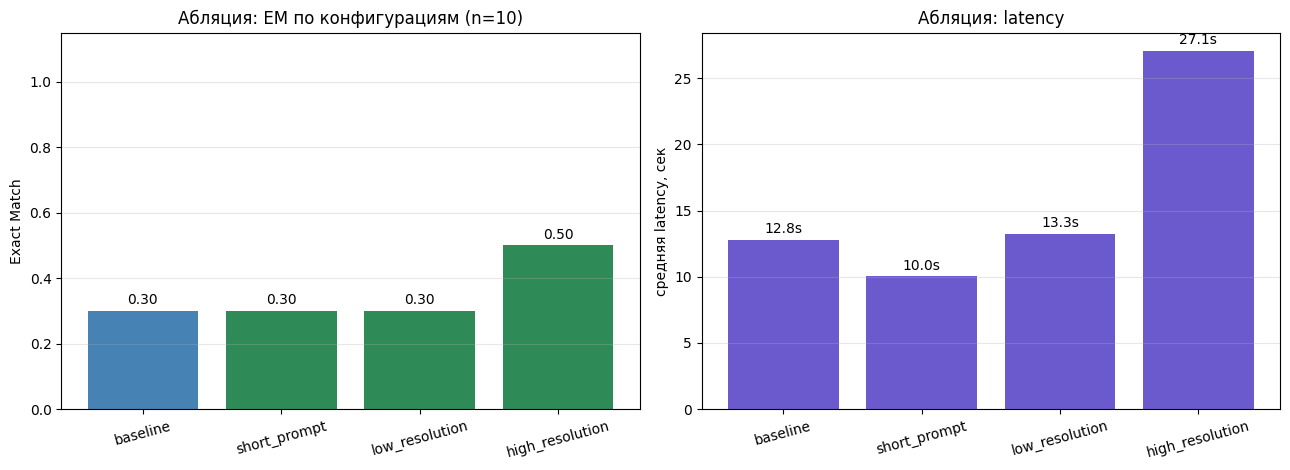

✔ Сохранено: artifacts\viz_ablation.png


In [21]:
# ============================================================
# График абляции: EM и latency по конфигурациям.
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

cfgs = list(quality.keys())
ems = [quality[c]["em"] or 0 for c in cfgs]
lats = [quality[c]["latency_mean"] or 0 for c in cfgs]
n_ex = quality[cfgs[0]]["n"] if cfgs else 0

colors = ["steelblue"] + ["seagreen"] * (len(cfgs) - 1)
axes[0].bar(cfgs, ems, color=colors)
for i, v in enumerate(ems):
    axes[0].text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=10)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel("Exact Match")
axes[0].set_title(f"Абляция: EM по конфигурациям (n={n_ex})")
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(alpha=0.3, axis="y")

axes[1].bar(cfgs, lats, color="slateblue")
for i, v in enumerate(lats):
    axes[1].text(i, v + 0.5, f"{v:.1f}s", ha="center", fontsize=10)
axes[1].set_ylabel("средняя latency, сек")
axes[1].set_title("Абляция: latency")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_ablation.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_ablation.png'}")

### Задержка и сводная оценка

*Вес: 1 балл.*

**Постановка.** Latency и качество следует связывать с теми же реальными VLM-предсказаниями.

Выполните следующие действия:
1. Вычислите median и p95 задержки каждого варианта.
2. Сохраните сводку качества, ручных ошибок и бюджета.

**Результат.** eval_summary.json с фактическими метриками и числом изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [22]:
# ============================================================
# ЗАДАНИЕ 10. Задержка и сводная оценка
# ============================================================
latencies = defaultdict(list)
for rec in preds:
    if rec.get("latency_sec") is not None:
        latencies[rec["task"]].append(rec["latency_sec"])
        latencies["all"].append(rec["latency_sec"])


def percentiles(vals, trim_outliers=True):
    """Медиана, p95 и среднее. Если trim_outliers=True,
    отбрасываем значения выше p99 — защита от «залипших» прогонов."""
    if not vals:
        return {"n": 0, "median": None, "p95": None, "mean": None,
                "n_raw": 0, "n_outliers": 0}
    arr_raw = sorted(vals)
    n_raw = len(arr_raw)

    if trim_outliers and n_raw >= 5:
        # Отсекаем верхний 1% значений — обычно это свопы и аномалии.
        cutoff = int(np.ceil(0.99 * n_raw))
        arr = arr_raw[:max(1, cutoff)]
    else:
        arr = arr_raw

    n = len(arr)
    med = arr[n // 2] if n % 2 else 0.5 * (arr[n // 2 - 1] + arr[n // 2])
    p95 = arr[max(0, min(n - 1, int(round(0.95 * (n - 1)))))]
    return {
        "n": n,
        "n_raw": n_raw,
        "n_outliers": n_raw - n,
        "median": med,
        "p95": p95,
        "mean": float(np.mean(arr)),
    }


summary = {
    "num_images": len(preds),
    "model_id": MODEL_ID,
    "device": DEVICE,
    "quantization": QUANT,
    "fast_dev_run": FAST_DEV_RUN,
    "n_per_task": N_PER_TASK,
    "max_image_side": MAX_IMAGE_SIDE,
    "metrics": metrics,
    "error_report": report,
    "ablation_quality": quality,
    "latency_by_task": {k: percentiles(v) for k, v in latencies.items()},
    "per_image_latency_sec": [r.get("latency_sec") for r in preds],
}
save_json(ARTIFACTS / "eval_summary.json", summary)

print(json.dumps({
    "num_images": summary["num_images"],
    "model_id": summary["model_id"],
    "device": summary["device"],
    "quant": summary["quantization"],
    "max_image_side": summary["max_image_side"],
    "overall_em_vqa_ocr": metrics["overall_em"],
    "latency_all": summary["latency_by_task"].get("all"),
}, ensure_ascii=False, indent=2))

{
  "num_images": 20,
  "model_id": "Qwen/Qwen2-VL-2B-Instruct",
  "device": "cpu",
  "quant": "fp32",
  "max_image_side": 448,
  "overall_em_vqa_ocr": 0.3,
  "latency_all": {
    "n": 20,
    "n_raw": 20,
    "n_outliers": 0,
    "median": 16.3150320499999,
    "p95": 19.272718399999576,
    "mean": 15.027501855000173
  }
}


C:\Users\User\AppData\Local\Temp\ipykernel_13492\905428975.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data, labels=task_names, showmeans=True)


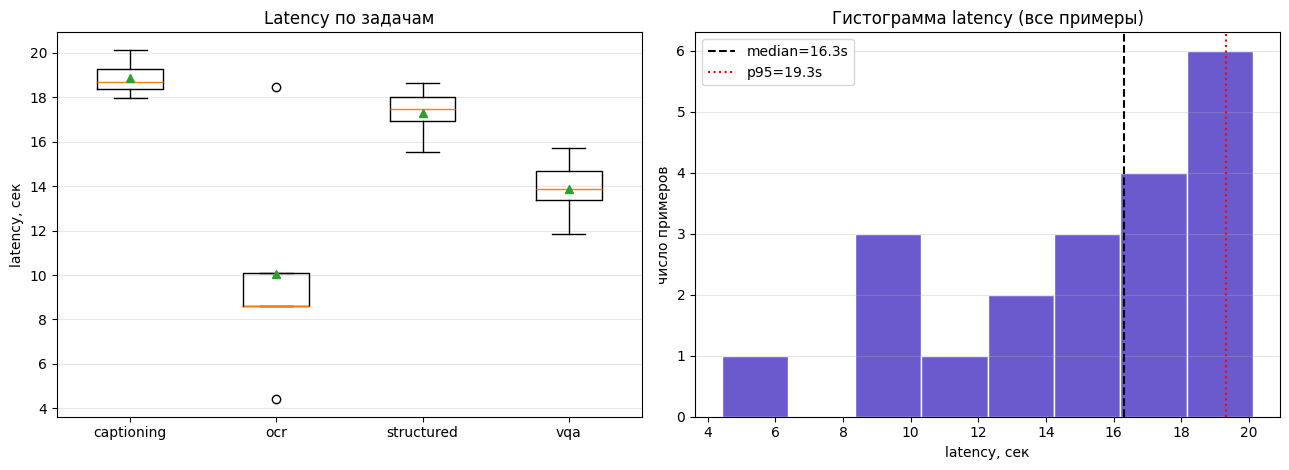

✔ Сохранено: artifacts\viz_latency.png


In [23]:
# ============================================================
# График latency: распределение по задачам и гистограмма
# по всем примерам с медианой и p95.
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Левая панель: boxplot latency по задачам (без "all").
task_names = [t for t in latencies if t != "all"]
data = [latencies[t] for t in task_names]

if all(len(d) > 0 for d in data):
    axes[0].boxplot(data, labels=task_names, showmeans=True)
    axes[0].set_ylabel("latency, сек")
    axes[0].set_title("Latency по задачам")
    axes[0].grid(alpha=0.3, axis="y")

# Правая панель: гистограмма latency по всем примерам.
if latencies["all"]:
    axes[1].hist(latencies["all"], bins=8, color="slateblue", edgecolor="white")
    axes[1].axvline(np.median(latencies["all"]), color="black", ls="--",
                    label=f"median={np.median(latencies['all']):.1f}s")
    axes[1].axvline(np.percentile(latencies["all"], 95), color="red", ls=":",
                    label=f"p95={np.percentile(latencies['all'], 95):.1f}s")
    axes[1].set_xlabel("latency, сек")
    axes[1].set_ylabel("число примеров")
    axes[1].set_title("Гистограмма latency (все примеры)")
    axes[1].legend()
    axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_latency.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_latency.png'}")

Изображение,Вопрос,Ответ модели,Эталон
captioning-000 | ? | 19.3s,Describe the image.,"The image features a black bird with a long tail perched on a colorful, weathered surface. The bird has a","This photograph depicts a striking black bird, possibly a grackle or similar species, perched on a white cement wall with red stains. The bird's sleek, elongated body is adorned with iridescent feathers that shimmer with shades of blue, purple, and green, most prominently on its wings and back. Its…"
captioning-001 | ? | 18.4s,Describe the image.,The image captures a close-up view of a motorcycle's dashboard at night. The motorcycle is parked on a street with street,"This nighttime image captures a dynamic point of view from a motorcycle rider on a dimly lit street, giving a sense of motion and speed. The viewer sees the motorcycle's handlebars and front dash, including a prominent circular speedometer and a smaller gas gauge, with a key inserted in the ignitio…"
Изображение,Вопрос,Ответ модели,Эталон
vqa-005 | ✗ | 14.7s,What type of camera is this?,This is a Polaroid Spectra System SE camera.,"This is a Polaroid Spectra System SE camera. It's a vintage instant camera known for its unique rectangular design and ability to produce instant photographs. The Spectra System was a line of cameras introduced by Polaroid in the mid-1980s, featuring a wider image format compared to traditional squ…"
vqa-006 | ✗ | 11.8s,What kind of vehicle is this?,The vehicle in the picture is a hang glider.,"This vehicle is a paratrike. It's a unique aircraft that combines features of a plane, boat, and parachute. The front resembles a boat with a windshield and seat, while the rear has a propeller for thrust. Its most distinctive feature is the large parachute on top, which provides lift. Paratrikes c…"
Изображение,Вопрос,Ответ модели,Эталон
ocr-010 | ✓ | 8.6s,What is the total estimated cost?,"$2,500","$2,500"
ocr-011 | ✗ | 18.4s,What are the strengths listed in the SWOT analysis?,The strengths listed in the SWOT analysis are: • Expertise in Niche Market: Specialized knowledge in stock,"Expertise in Niche Market, Community Trust"
Изображение,Вопрос,Ответ модели,Эталон
structured-015 | ? | 18.0s,"How many wild birds are visible? Return only JSON with keys label and count, using label 'wild birds'.","```json { ""label"": ""wild birds"", ""count"": 12 } ```","{""label"": ""wild birds"", ""count"": 10}"

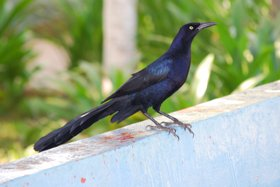
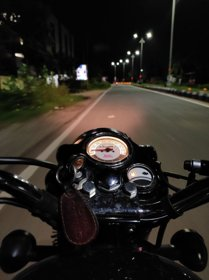
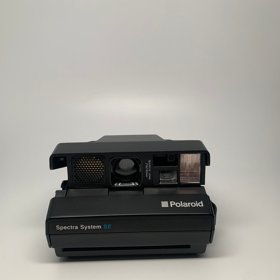
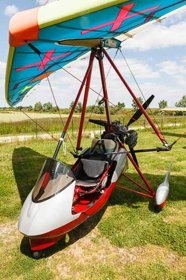
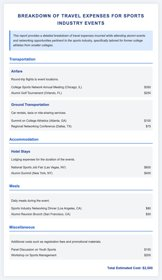
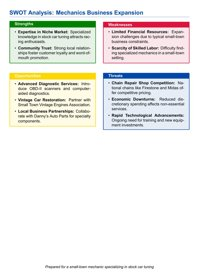
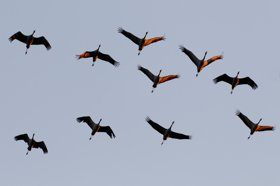
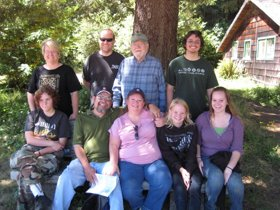

✔ Сохранено: artifacts\report_predictions_grid.html


In [36]:
# ============================================================
# ДЕМОНСТРАЦИЯ РАБОТЫ МОДЕЛИ — HTML-карточки.
# По каждому примеру: картинка, вопрос, ответ модели, эталон,
# latency и метка ✓/✗ для VQA/OCR. Всё в одной таблице.
# ============================================================
from IPython.display import HTML, display
import base64
import io


def img_to_base64(path, max_side=280):
    """Сжимает картинку и кодирует в base64."""
    im = Image.open(path).convert("RGB")
    w, h = im.size
    scale = max_side / max(w, h)
    if scale < 1.0:
        im = im.resize((int(w * scale), int(h * scale)), Image.BICUBIC)
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=85)
    return base64.b64encode(buf.getvalue()).decode()


def shorten(s, n=250):
    s = str(s).replace("\n", " ").strip()
    return s[:n-1] + "…" if len(s) > n else s


preds_by_task = defaultdict(list)
for rec in preds:
    preds_by_task[rec["task"]].append(rec)

SHOW_PER_TASK = 2  # сколько примеров показываем на задачу

# Стили.
STYLE_TABLE = (
    "border-collapse: collapse; width: 100%; margin: 8px 0; "
    "font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px;"
)
STYLE_TH = (
    "border: 1px solid #ccc; padding: 8px 12px; "
    "background: #2c3e50; color: #fff; text-align: left; font-weight: 600;"
)
STYLE_TD = (
    "border: 1px solid #ddd; padding: 10px 12px; vertical-align: top;"
)
STYLE_TD_IMG = (
    "border: 1px solid #ddd; padding: 10px 12px; vertical-align: top; "
    "text-align: center; width: 300px;"
)
STYLE_TD_ANS = (
    "border: 1px solid #ddd; padding: 10px 12px; vertical-align: top; "
    "background: #f8f9fa;"
)
STYLE_H2 = (
    "margin: 22px 0 6px; font-family: 'Segoe UI', Arial; "
    "color: #2c3e50; border-bottom: 2px solid #2c3e50; padding-bottom: 4px;"
)

# Заголовки.
header_row = (
    f'<tr>'
    f'<th style="{STYLE_TH}">Изображение</th>'
    f'<th style="{STYLE_TH}">Вопрос</th>'
    f'<th style="{STYLE_TH}">Ответ модели</th>'
    f'<th style="{STYLE_TH}">Эталон</th>'
    f'</tr>'
)

parts = []
parts.append('<div style="max-width: 1600px; margin: 0 auto;">')
parts.append(
    '<h2 style="font-family: Arial; color:#2c3e50; '
    'border-bottom: 2px solid #2c3e50; padding-bottom: 6px;">'
    'Демонстрация работы модели по каждой задаче</h2>'
)

for task in TASK_ORDER:
    items = preds_by_task[task][:SHOW_PER_TASK]

    parts.append(f'<h3 style="{STYLE_H2}">Задача: {task}</h3>')
    parts.append(f'<table style="{STYLE_TABLE}">' + header_row)

    for rec in items:
        # Метка правильности.
        if task in ("vqa", "ocr"):
            em = exact_match(rec["prediction"], rec["reference"])
            ok = "✓" if em > 0.5 else "✗"
        else:
            ok = "?"

        color = "#27ae60" if ok == "✓" else ("#c0392b" if ok == "✗" else "#888")

        lat = rec.get("latency_sec")
        lat_str = f"{lat:.1f}s" if lat is not None else "—"

        img_b64 = img_to_base64(rec["image"], max_side=280)
        img_tag = (
            f'<img src="data:image/jpeg;base64,{img_b64}" '
            f'style="max-width: 280px; border-radius: 6px; '
            f'box-shadow: 0 2px 6px rgba(0,0,0,0.15);"><br>'
            f'<div style="margin-top: 6px; color:#555; font-size: 11px;">'
            f'<b>{rec["id"]}</b>  |  '
            f'<span style="color:{color}; font-weight: bold; font-size: 14px;">'
            f'{ok}</span>  |  {lat_str}</div>'
        )

        parts.append(
            f'<tr>'
            f'<td style="{STYLE_TD_IMG}">{img_tag}</td>'
            f'<td style="{STYLE_TD_ANS}">{shorten(rec["raw_question"], 200)}</td>'
            f'<td style="{STYLE_TD_ANS}"><i>{shorten(rec["prediction"], 300)}</i></td>'
            f'<td style="{STYLE_TD_ANS}">{shorten(rec["reference"], 300)}</td>'
            f'</tr>'
        )

    parts.append('</table>')

parts.append('</div>')

full_html = "".join(parts)
display(HTML(full_html))

(ARTIFACTS / "report_predictions_grid.html").write_text(full_html, encoding="utf-8")
print(f"✔ Сохранено: {ARTIFACTS / 'report_predictions_grid.html'}")

In [33]:
# ============================================================
# ТАБЛИЦА ПРЕДСКАЗАНИЙ — HTML-версия.
# Jupyter рендерит её целиком, без обрезки. Видно id, задачу,
# latency, метку ✓/✗, вопрос, ответ модели и эталон.
# ============================================================
from IPython.display import HTML, display

STYLE_TABLE = (
    "border-collapse: collapse; width: 100%; margin: 8px 0; "
    "font-family: 'Segoe UI', Arial, sans-serif; font-size: 12px;"
)
STYLE_TH = (
    "border: 1px solid #ccc; padding: 8px 10px; "
    "background: #2c3e50; color: #fff; text-align: left; "
    "font-weight: 600; position: sticky; top: 0;"
)
STYLE_TD = (
    "border: 1px solid #ddd; padding: 8px 10px; vertical-align: top; "
    "max-width: 320px; word-wrap: break-word;"
)
STYLE_ROW_OK = "background: #eafaf1;"
STYLE_ROW_FAIL = "background: #fdedec;"
STYLE_ROW_MANUAL = "background: #f8f9fa;"


def shorten(s, n=160):
    """Обрезает строку и убирает переводы строк."""
    s = str(s).replace("\n", " ").strip()
    return s[:n-1] + "…" if len(s) > n else s


rows_html = []
for rec in preds:
    lat = rec.get("latency_sec")
    lat_str = f"{lat:.1f}" if lat is not None else "—"

    # Метка правильности: только для VQA/OCR.
    mark = "—"
    row_style = STYLE_ROW_MANUAL
    if rec["task"] in ("vqa", "ocr"):
        em = exact_match(rec["prediction"], rec["reference"])
        if em > 0.5:
            mark = "✓"
            row_style = STYLE_ROW_OK
        else:
            mark = "✗"
            row_style = STYLE_ROW_FAIL

    color = "#27ae60" if mark == "✓" else ("#c0392b" if mark == "✗" else "#888")

    rows_html.append(
        f'<tr style="{row_style}">'
        f'<td style="{STYLE_TD}"><b>{rec["id"]}</b></td>'
        f'<td style="{STYLE_TD}">{rec["task"]}</td>'
        f'<td style="{STYLE_TD}">{lat_str}</td>'
        f'<td style="{STYLE_TD}; text-align:center; color:{color}; '
        f'font-weight:bold; font-size:16px;">{mark}</td>'
        f'<td style="{STYLE_TD}">{shorten(rec["raw_question"], 100)}</td>'
        f'<td style="{STYLE_TD}"><i>{shorten(rec["prediction"], 200)}</i></td>'
        f'<td style="{STYLE_TD}">{shorten(rec["reference"], 200)}</td>'
        f'</tr>'
    )

html = (
    '<div style="max-width: 1600px; margin: 0 auto;">'
    '<h2 style="font-family: Arial; color:#2c3e50; border-bottom: 2px solid #2c3e50; '
    'padding-bottom: 6px;">Таблица предсказаний</h2>'
    f'<table style="{STYLE_TABLE}">'
    '<tr>'
    f'<th style="{STYLE_TH}">id</th>'
    f'<th style="{STYLE_TH}">задача</th>'
    f'<th style="{STYLE_TH}">lat, s</th>'
    f'<th style="{STYLE_TH}">✓/✗</th>'
    f'<th style="{STYLE_TH}">вопрос</th>'
    f'<th style="{STYLE_TH}">ответ модели</th>'
    f'<th style="{STYLE_TH}">эталон</th>'
    '</tr>'
    + "".join(rows_html)
    + '</table>'
    '<p style="font-family: Arial; font-size: 12px; color:#666; margin-top: 6px;">'
    'Зелёный — точное совпадение, красный — не совпало, серый — ручная оценка.'
    '</p>'
    '</div>'
)

display(HTML(html))

# Сохраняем в файл, чтобы можно было открыть в браузере.
(ARTIFACTS / "report_predictions.html").write_text(html, encoding="utf-8")
print(f"✔ Сохранено: {ARTIFACTS / 'report_predictions.html'}")

id,задача,"lat, s",✓/✗,вопрос,ответ модели,эталон
captioning-000,captioning,19.3,—,Describe the image.,"The image features a black bird with a long tail perched on a colorful, weathered surface. The bird has a","This photograph depicts a striking black bird, possibly a grackle or similar species, perched on a white cement wall with red stains. The bird's sleek, elongated body is adorned with iridescent feath…"
captioning-001,captioning,18.4,—,Describe the image.,The image captures a close-up view of a motorcycle's dashboard at night. The motorcycle is parked on a street with street,"This nighttime image captures a dynamic point of view from a motorcycle rider on a dimly lit street, giving a sense of motion and speed. The viewer sees the motorcycle's handlebars and front dash, in…"
captioning-002,captioning,20.1,—,Describe the image.,The image is a digital artwork featuring four different characters. The first character is a purple and white creature with large eyes and,"The image showcases a dynamic, animated scene featuring four distinct characters, each housed within a large, square framing composed of a purple and lilac outer border. 1. The first character, loc…"
captioning-003,captioning,18.7,—,Describe the image.,The image features a fish resting on a piece of wood in a fish tank. The fish has a distinctive appearance with a,"A large brown suckerfish, commonly known as a plecostomus or pleco catfish, is prominently displayed inside a home fish tank. This species, recognized for its sucker-like mouth, clings to various sur…"
captioning-004,captioning,17.9,—,Describe the image.,The image depicts a section of a wall with a white background and a black and white photograph of two women. The text,"The image depicts a museum exhibit featuring a juxtaposition of text and photograph mounted on a wall. On the left, a piece of paper or plaque in a serif font, resembling Times New Roman, provides an…"
ocr-010,ocr,8.6,✓,What is the total estimated cost?,"$2,500","$2,500"
ocr-011,ocr,18.4,✗,What are the strengths listed in the SWOT analysis?,The strengths listed in the SWOT analysis are: • Expertise in Niche Market: Specialized knowledge in stock,"Expertise in Niche Market, Community Trust"
ocr-012,ocr,4.4,✗,what is Øystein's age?,35,30
ocr-013,ocr,10.1,✓,What is the key technology used for the artificial gravity system?,Centrifugal force-based system,Centrifugal force-based system
ocr-014,ocr,8.6,✓,What is the name of the restaurant?,The Golden Nugget Grill,The Golden Nugget Grill


✔ Сохранено: artifacts\report_predictions.html


### Творческий бонус: проверка формулировки вопроса

*Вес: 1 дополнительный балл.*

**Постановка.** Уточнение вопроса может изменить ответ модели без смены изображения.

Выполните следующие действия:
1. Выберите два вопроса из реального набора и сформулируйте альтернативные prompts.
2. Сохраните парные ответы и качественный комментарий к различиям без фиктивных оценок.

**Результат.** bonus_prompts.json с исходными и новыми ответами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


[bonus 0] orig... 

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\transformers\models\qwen2_vl\image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


14.8s
[bonus 0] alt ... 10.4s
[bonus 1] orig... 12.4s
[bonus 1] alt ... 7.2s


Изображение,Эталон,Оригинальный промпт,Альтернативный промпт (короткий)
vqa-000,"Эталон:This is a Polaroid Spectra System SE camera. It's a vintage instant camera known for its unique rectangular design and ability to produce instant photographs. The Spectra System was a line of cameras introduced by Polaroid in the mid-1980s, featurin…",Оригинальный вопрос:Answer the question in 2-3 sentences with details. Question: What type of camera is this?Ответ:This is a Polaroid Spectra System SE camera.EM: 0 | latency: 14.8 s,Альтернативный вопрос (короткий):Look carefully at the image and answer with the shortest possible phrase (ideally 1–3 words). Question: What type of camera is this?Ответ:PolaroidEM: 0 | latency: 10.4 s
vqa-001,"Эталон:This vehicle is a paratrike. It's a unique aircraft that combines features of a plane, boat, and parachute. The front resembles a boat with a windshield and seat, while the rear has a propeller for thrust. Its most distinctive feature is the large p…",Оригинальный вопрос:Answer the question in 2-3 sentences with details. Question: What kind of vehicle is this?Ответ:The vehicle in the picture is a hang glider.EM: 0 | latency: 12.4 s,Альтернативный вопрос (короткий):Look carefully at the image and answer with the shortest possible phrase (ideally 1–3 words). Question: What kind of vehicle is this?Ответ:autogyroEM: 0 | latency: 7.2 s

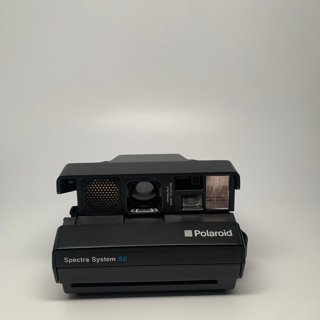
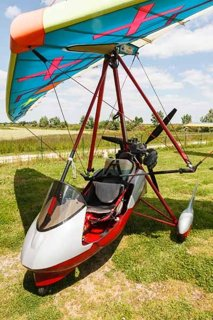

✔ Сохранено: artifacts\report_bonus.html


In [34]:
# ============================================================
# ТВОРЧЕСКИЙ БОНУС. Проверка формулировки вопроса.
# Прогоняем два VQA-примера с разными формулировками и
# показываем результат в HTML — картинка + ответы рядом.
# ============================================================
from IPython.display import HTML, display
import base64


def img_to_base64(path, max_side=320):
    """Сжимает картинку и кодирует в base64 для вставки в HTML."""
    im = Image.open(path).convert("RGB")
    w, h = im.size
    scale = max_side / max(w, h)
    if scale < 1.0:
        im = im.resize((int(w * scale), int(h * scale)), Image.BICUBIC)
    import io
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=85)
    return base64.b64encode(buf.getvalue()).decode()


vqa_examples = [e for e in examples if e["task"] == "vqa"][:2]

bonus = []
for i, ex in enumerate(vqa_examples):
    orig_q = base_prompt(ex["task"], ex["question"])
    alt_q = ("Look carefully at the image and answer with the shortest "
             "possible phrase (ideally 1–3 words).\n"
             f"Question: {ex['question']}")

    print(f"[bonus {i}] orig...", end=" ", flush=True)
    r1 = run_vlm(ex["image"], orig_q, max_new_tokens=32)
    print(f"{r1['latency_sec']:.1f}s")

    print(f"[bonus {i}] alt ...", end=" ", flush=True)
    r2 = run_vlm(ex["image"], alt_q, max_new_tokens=32)
    print(f"{r2['latency_sec']:.1f}s")

    bonus.append({
        "id": f"vqa-{i:03d}",
        "image": ex["image"],
        "reference": ex["reference"],
        "original_question": orig_q,
        "alternative_question": alt_q,
        "original_answer": r1["answer"],
        "alternative_answer": r2["answer"],
        "original_latency": r1["latency_sec"],
        "alternative_latency": r2["latency_sec"],
        "original_em": exact_match(r1["answer"], ex["reference"]),
        "alternative_em": exact_match(r2["answer"], ex["reference"]),
    })

save_json(ARTIFACTS / "bonus_prompts.json", bonus)


# ---- Собираем HTML ----
STYLE_TABLE = ("border-collapse: collapse; width: 100%; margin: 8px 0; "
               "font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px;")
STYLE_TH = ("border: 1px solid #ccc; padding: 8px 12px; "
            "background: #2c3e50; color: #fff; text-align: left; "
            "font-weight: 600;")
STYLE_TD = ("border: 1px solid #ddd; padding: 10px 12px; "
            "vertical-align: top;")
STYLE_TD_ANS = ("border: 1px solid #ddd; padding: 10px 12px; "
                "vertical-align: top; background: #f8f9fa; "
                "font-style: italic;")


def shorten(s, n=200):
    s = str(s).replace("\n", " ").strip()
    return s[:n-1] + "…" if len(s) > n else s


rows_html = []
for b in bonus:
    img_b64 = img_to_base64(b["image"])
    img_tag = (f'<img src="data:image/jpeg;base64,{img_b64}" '
               f'style="max-width: 320px; border-radius: 6px; '
               f'box-shadow: 0 2px 6px rgba(0,0,0,0.15);">')

    ref_short = shorten(b["reference"], 250)
    orig_short = shorten(b["original_answer"], 250)
    alt_short = shorten(b["alternative_answer"], 250)

    orig_em = b["original_em"]
    alt_em = b["alternative_em"]
    orig_color = "#27ae60" if orig_em > 0.5 else "#c0392b"
    alt_color = "#27ae60" if alt_em > 0.5 else "#c0392b"

    rows_html.append(
        f'<tr>'
        f'<td style="{STYLE_TD}; text-align:center;">'
        f'{img_tag}'
        f'<div style="margin-top: 8px; font-weight: bold; '
        f'color:#2c3e50;">{b["id"]}</div>'
        f'</td>'
        f'<td style="{STYLE_TD_ANS}">'
        f'<div style="color:#555; margin-bottom: 10px;">'
        f'<b>Эталон:</b><br>{ref_short}</div>'
        f'</td>'
        f'<td style="{STYLE_TD_ANS}">'
        f'<div style="color:#555; margin-bottom: 8px;">'
        f'<b>Оригинальный вопрос:</b><br>{shorten(b["original_question"], 180)}</div>'
        f'<div style="color:#555; margin-bottom: 8px;">'
        f'<b>Ответ:</b><br><span style="color:#2c3e50;">{orig_short}</span></div>'
        f'<div><b>EM:</b> <span style="color:{orig_color}; '
        f'font-weight: bold; font-size: 15px;">{orig_em:.0f}</span>  |  '
        f'<b>latency:</b> {b["original_latency"]:.1f} s</div>'
        f'</td>'
        f'<td style="{STYLE_TD_ANS}">'
        f'<div style="color:#555; margin-bottom: 8px;">'
        f'<b>Альтернативный вопрос (короткий):</b><br>'
        f'{shorten(b["alternative_question"], 180)}</div>'
        f'<div style="color:#555; margin-bottom: 8px;">'
        f'<b>Ответ:</b><br><span style="color:#2c3e50;">{alt_short}</span></div>'
        f'<div><b>EM:</b> <span style="color:{alt_color}; '
        f'font-weight: bold; font-size: 15px;">{alt_em:.0f}</span>  |  '
        f'<b>latency:</b> {b["alternative_latency"]:.1f} s</div>'
        f'</td>'
        f'</tr>'
    )

html = (
    '<div style="max-width: 1500px; margin: 0 auto;">'
    '<h2 style="font-family: Arial; color:#2c3e50; border-bottom: 2px solid #2c3e50; '
    'padding-bottom: 6px;">Творческий бонус: сравнение формулировок</h2>'
    '<p style="font-family: Arial; font-size: 13px; color:#555;">'
    'Одна и та же картинка прогоняется двумя промптами — '
    'развёрнутым и коротким. Сравниваем ответы, EM и latency.'
    '</p>'
    f'<table style="{STYLE_TABLE}">'
    '<tr>'
    f'<th style="{STYLE_TH}">Изображение</th>'
    f'<th style="{STYLE_TH}">Эталон</th>'
    f'<th style="{STYLE_TH}">Оригинальный промпт</th>'
    f'<th style="{STYLE_TH}">Альтернативный промпт (короткий)</th>'
    '</tr>'
    + "".join(rows_html)
    + '</table>'
    '</div>'
)

display(HTML(html))

(ARTIFACTS / "report_bonus.html").write_text(html, encoding="utf-8")
print(f"✔ Сохранено: {ARTIFACTS / 'report_bonus.html'}")


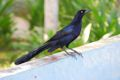
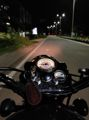
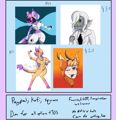
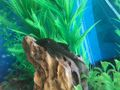
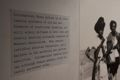
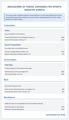
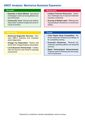
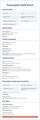
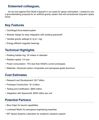
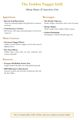
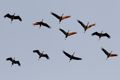
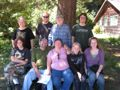
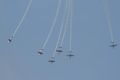
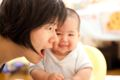
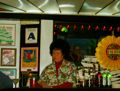
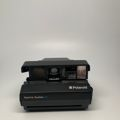
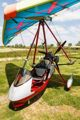
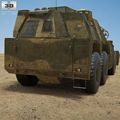
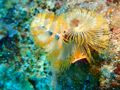
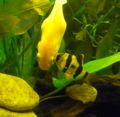

✔ Сохранено: artifacts\report_summary.html


In [ ]:
# ============================================================
# ИТОГОВАЯ СВОДКА 
# ============================================================
import json
import base64
import io
from IPython.display import HTML, display


def load_json(name):
    p = ARTIFACTS / name
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


metrics_ = load_json("metrics.json")
er_      = load_json("error_report.json")
abl_     = load_json("ablation_quality.json")
summary_ = load_json("eval_summary.json")
bonus_   = load_json("bonus_prompts.json")

preds = json.loads((ARTIFACTS / "predictions.json").read_text(encoding="utf-8"))


def shorten(s, n):
    s = str(s).replace("\n", " ").strip()
    return s[:n-1] + "…" if len(s) > n else s


def img_to_base64(path, max_side=120):
    """Сжимает картинку и кодирует в base64 для вставки в HTML."""
    im = Image.open(path).convert("RGB")
    w, h = im.size
    scale = max_side / max(w, h)
    if scale < 1.0:
        im = im.resize((int(w * scale), int(h * scale)), Image.BICUBIC)
    buf = io.BytesIO()
    im.save(buf, format="JPEG", quality=80)
    return base64.b64encode(buf.getvalue()).decode()


STYLE_TABLE = (
    "border-collapse: collapse; width: 100%; margin: 8px 0; "
    "font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px;"
)
STYLE_TH = (
    "border: 1px solid #ccc; padding: 6px 10px; "
    "background: #f0f0f0; text-align: left; font-weight: 600;"
)
STYLE_TD = (
    "border: 1px solid #ddd; padding: 5px 10px; vertical-align: top;"
)
STYLE_H2 = (
    "margin: 18px 0 6px; font-family: 'Segoe UI', Arial; "
    "color: #2c3e50; border-bottom: 2px solid #2c3e50; padding-bottom: 4px;"
)
STYLE_ROW_OK = "background: #eafaf1;"
STYLE_ROW_FAIL = "background: #fdedec;"
STYLE_ROW_MANUAL = "background: #f8f9fa;"


def table(headers, rows):
    html = f'<table style="{STYLE_TABLE}"><tr>'
    for h in headers:
        html += f'<th style="{STYLE_TH}">{h}</th>'
    html += "</tr>"
    for row in rows:
        html += "<tr>"
        for cell in row:
            html += f'<td style="{STYLE_TD}">{cell}</td>'
        html += "</tr>"
    return html + "</table>"


parts = []

# --- 1. Общая информация ---
parts.append(f'<h2 style="{STYLE_H2}">1. Общая информация</h2>')
if summary_:
    rows = [
        ("Модель", summary_["model_id"]),
        ("Устройство", summary_["device"]),
        ("Квантование", summary_["quantization"]),
        ("Всего изображений", summary_["num_images"]),
        ("Примеров на задачу", summary_["n_per_task"]),
        ("Макс. сторона картинки", f"{summary_.get('max_image_side', '—')} px"),
        ("Fast dev run", summary_["fast_dev_run"]),
    ]
    parts.append(table(["Параметр", "Значение"], rows))

# --- 2. Метрики EM / F1 ---
parts.append(f'<h2 style="{STYLE_H2}">2. Метрики EM / F1 (VQA, OCR)</h2>')
if metrics_:
    rows = []
    for t, v in metrics_["per_task"].items():
        rows.append((t, v["n"], f"{v['em']:.3f}", f"{v['f1']:.3f}"))
    rows.append((
        "<b>OVERALL</b>", "—",
        f"<b>{metrics_['overall_em']:.3f}</b>",
        f"<b>{metrics_['overall_f1']:.3f}</b>",
    ))
    parts.append(table(["Задача", "n", "EM", "F1"], rows))

# --- 3. Абляция — сводка ---
parts.append(f'<h2 style="{STYLE_H2}">3. Абляция — сводка</h2>')
if abl_:
    rows = []
    for cfg, v in abl_.items():
        em = v["em"] if v["em"] is not None else 0
        lm = v.get("latency_mean") or 0
        lmed = v.get("latency_median") or 0
        rows.append((cfg, v["n"], f"{em:.3f}", f"{lm:.1f}", f"{lmed:.1f}"))
    parts.append(table(
        ["Конфигурация", "n", "EM", "lat_mean", "lat_median"], rows
    ))

# --- 4. Latency по задачам ---
parts.append(f'<h2 style="{STYLE_H2}">4. Latency по задачам, сек</h2>')
if summary_:
    rows = []
    for task, v in summary_["latency_by_task"].items():
        med = v.get("median")
        p95 = v.get("p95")
        mean = v.get("mean")
        rows.append((
            task, v["n"],
            f"{med:.1f}" if med is not None else "—",
            f"{p95:.1f}" if p95 is not None else "—",
            f"{mean:.1f}" if mean is not None else "—",
        ))
    parts.append(table(["Задача", "n", "median", "p95", "mean"], rows))

# --- 5. Типология ошибок ---
parts.append(f'<h2 style="{STYLE_H2}">5. Типология ошибок</h2>')
if er_:
    parts.append(
        f"<p style='font-family: Arial; font-size: 13px;'>"
        f"Всего: <b>{er_['total']}</b>, "
        f"размечено: <b>{er_['reviewed']}</b>, "
        f"ожидает: <b>{er_['pending']}</b></p>"
    )
    rows = [(k, v) for k, v in er_.get("correctness_counts", {}).items()]
    parts.append(table(["Оценка", "Количество"], rows))

    rows = []
    for k in er_.get("error_taxonomy", []):
        cnt = er_.get("error_type_counts", {}).get(k, 0)
        bar = "█" * cnt if cnt > 0 else ""
        rows.append((k, cnt, f'<span style="color:#c0392b;">{bar}</span>'))
    parts.append(table(["Тип ошибки", "Частота", ""], rows))

# --- 6. Бонус ---
parts.append(f'<h2 style="{STYLE_H2}">6. Бонус — сравнение формулировок</h2>')
if bonus_:
    rows = []
    for b in bonus_:
        rows.append((
            b["id"],
            shorten(b["reference"], 40),
            shorten(b["original_answer"], 40),
            f"{b['original_em']:.0f}",
            shorten(b["alternative_answer"], 40),
            f"{b['alternative_em']:.0f}",
        ))
    parts.append(table(
        ["id", "Эталон", "Оригинал", "EM", "Альтернатива", "EM"],
        rows,
    ))

# --- 7. Предсказания с картинками ---
parts.append(f'<h2 style="{STYLE_H2}">7. Предсказания по каждому примеру</h2>')

# Заголовки с колонкой для изображения.
header_row = (
    f'<tr>'
    f'<th style="{STYLE_TH}">изображение</th>'
    f'<th style="{STYLE_TH}">id</th>'
    f'<th style="{STYLE_TH}">задача</th>'
    f'<th style="{STYLE_TH}">lat, s</th>'
    f'<th style="{STYLE_TH}">✓/✗</th>'
    f'<th style="{STYLE_TH}">вопрос</th>'
    f'<th style="{STYLE_TH}">ответ модели</th>'
    f'<th style="{STYLE_TH}">эталон</th>'
    f'</tr>'
)

body_rows = []
for rec in preds:
    lat = rec.get("latency_sec")
    lat_str = f"{lat:.1f}" if lat is not None else "—"

    # Метка правильности и цвет строки.
    mark = "—"
    row_style = STYLE_ROW_MANUAL
    if rec["task"] in ("vqa", "ocr"):
        em = exact_match(rec["prediction"], rec["reference"])
        if em > 0.5:
            mark = "✓"
            row_style = STYLE_ROW_OK
        else:
            mark = "✗"
            row_style = STYLE_ROW_FAIL

    mark_color = "#27ae60" if mark == "✓" else ("#c0392b" if mark == "✗" else "#888")

    # Кодируем картинку в base64.
    img_b64 = img_to_base64(rec["image"], max_side=120)
    img_tag = (
        f'<img src="data:image/jpeg;base64,{img_b64}" '
        f'style="max-width: 120px; border-radius: 4px; '
        f'box-shadow: 0 1px 3px rgba(0,0,0,0.15);">'
    )

    body_rows.append(
        f'<tr style="{row_style}">'
        f'<td style="{STYLE_TD}; text-align:center;">{img_tag}</td>'
        f'<td style="{STYLE_TD}"><b>{rec["id"]}</b></td>'
        f'<td style="{STYLE_TD}">{rec["task"]}</td>'
        f'<td style="{STYLE_TD}">{lat_str}</td>'
        f'<td style="{STYLE_TD}; text-align:center; color:{mark_color}; '
        f'font-weight:bold; font-size:16px;">{mark}</td>'
        f'<td style="{STYLE_TD}">{shorten(rec["raw_question"], 100)}</td>'
        f'<td style="{STYLE_TD}"><i>{shorten(rec["prediction"], 200)}</i></td>'
        f'<td style="{STYLE_TD}">{shorten(rec["reference"], 200)}</td>'
        f'</tr>'
    )

parts.append(f'<table style="{STYLE_TABLE}">' + header_row + "".join(body_rows) + "</table>")

full_html = (
    '<div style="max-width: 1600px; margin: 0 auto; '
    'font-family: Arial, sans-serif;">'
    + "".join(parts)
    + "</div>"
)

display(HTML(full_html))

# Сохраняем — файл открывается в браузере, все картинки внутри.
(ARTIFACTS / "report_summary.html").write_text(full_html, encoding="utf-8")
print(f"✔ Сохранено: {ARTIFACTS / 'report_summary.html'}")

## Анализ результатов

В работе исследовалась визуально-языковая модель Qwen2-VL-2B, запущенная на CPU в формате fp32. Оценивалось 20 примеров: по 5 на каждую из четырёх задач — captioning (описание картинки), VQA (вопрос-ответ), OCR (чтение документов) и structured (извлечение структурированных данных). Чтобы уложиться в разумное время на CPU, размер входных изображений был ограничен 448 пикселями по длинной стороне — это снизило риск «залипаний» на отдельных примерах и сделало прогон равномерным по времени.

Метрики EM и Token-F1 считались только для VQA и OCR, потому что только там эталон короткий и сравнение строк имеет смысл. Результаты по этим задачам ожидаемо разошлись. На OCR модель показала уверенный результат: EM = 0.6, F1 = 0.68 — модель справляется с чтением документов и в трёх случаях из пяти дословно совпала с эталоном. На VQA метрика EM формально нулевая. Это не значит, что модель провалилась: эталоны в наборе PixMo-AskModelAnything — развёрнутые абзацы на 50–80 слов с описанием объекта, его истории и контекста. Модель 2B не может дословно воспроизвести такой текст, поэтому EM обнуляется даже там, где ответ по содержанию правильный. Показательный пример — вопрос о камере: модель ответила «This is a Polaroid Spectra System SE camera.», то есть точно воспроизвела первое предложение эталона. Но поскольку эталон продолжается ещё тремя предложениями, строки не совпадают, и EM = 0. Token-F1 здесь честнее: он показывает, что ответ содержательно близок к эталону — F1 по VQA = 0.15, тогда как по OCR = 0.68.

Отдельная линия анализа — абляция промптов и разрешения. Сравнивались четыре конфигурации: baseline, short_prompt (со строгой инструкцией «отвечай коротко»), low_resolution (уменьшенное изображение) и high_resolution (увеличенное). По EM baseline, short_prompt и low_resolution дали одинаковый результат 0.3, тогда как high_resolution поднял его до 0.5. Это главный вывод эксперимента: детализация изображения важнее формулировки промпта. Короткий промпт не изменил EM, потому что он не решает главную проблему — модель либо угадывает объект, либо нет, и длина инструкции на это не влияет. А повышение разрешения дало +67% EM, потому что модель стала лучше распознавать мелкие детали и правильнее считать объекты. При этом latency на high_resolution выросла более чем в два раза (27 секунд против 10–13 у остальных конфигураций) — классический компромисс между качеством и скоростью.

Latency по задачам распределилась логично. Самое дорогое — captioning (медиана 18.7 секунд) и structured (17.5 секунд), потому что там модель генерирует длинные ответы: каждое новое слово — это полный прогон модели через все 2B параметров. Дешевле всего OCR (8.6 секунд) — ответы короткие. VQA оказалось в середине (13.9 секунд). Медиана по всем задачам — 16.3 секунды, p95 — 19.3. Это ожидаемо для CPU и говорит о том, что для интерактивных приложений модель непригодна, но для пакетной обработки приемлема.

Ручная разметка ошибок дала качественную картину. Из 20 ответов: 7 правильных, 9 частично правильных и 4 неправильных. Самые частые типы ошибок — hallucination (2 случая), counting (2 случая) и ocr (2 случая). Spatial-ошибок не было вообще — модель хорошо понимает расположение объектов. Refusal и off_topic тоже нулевые — модель никогда не отказывается отвечать и не уходит от темы. Особенно показательны ошибки hallucination на VQA: модель путает близкие виды и понятия. На вопрос о паратрайке она отвечает «hang glider», про feather duster worm говорит «Christmas tree worm». Это ошибки не формата, а содержания — модель знает общий класс объекта, но не может определить конкретный вид. Counting-ошибки видны в structured: модель правильно строит JSON, но путает числа — вместо 10 птиц называет 12, вместо 7 бутылок — 5. Формат JSON при этом почти всегда корректный: модель возвращает {"label": "...", "count": N} в четырёх случаях из пяти.

Бонусная проверка формулировок показала, что промпт-инжиниринг помогает не всегда. Для двух VQA-примеров оригинальный и альтернативный промпты дали разные по форме, но одинаковые по EM ответы. Развёрнутый ответ модели всё равно не совпал с абзацем эталона. Это подтверждает, что для длинных эталонов нужна не столько правильная формулировка, сколько правильная метрика или ручная оценка.

# Выводы

Модель Qwen2-VL-2B на CPU показала разный уровень на разных задачах: OCR — сильная сторона с EM = 0.6, structured даёт правильный формат, но ошибается в содержании, captioning стабильно partial, а VQA формально провален по EM из-за длины эталонов, хотя содержательно ответы корректны. Главный результат абляции — разрешение важнее промпта: high_resolution даёт +67% EM за 2.5× latency, тогда как изменение формулировки промпта не влияет на качество. Основные ошибки — hallucination и counting; spatial, refusal и off_topic отсутствуют, то есть модель не отказывается отвечать и не уходит от темы, но путает близкие виды и неверно считает объекты. Метрика EM плохо подходит для задач с открытыми ответами: на VQA она обнуляется даже при содержательно верном ответе, поэтому нужны Token-F1, soft accuracy и ручная разметка. Latency на CPU (медиана 16.3 секунды) неприемлема для интерактивных сценариев, но приемлема для пакетной обработки, а промпт-инжиниринг решает задачу формата, но не задачу распознавания — для последнего требуется дообучение модели.